
# CineScope AI — 01: Data Audit

## Project Information

**Author:** Ankur Sharma

**Project:** CineScope AI

**Phase:** 2 — Data Acquisition & Preparation

**Notebook:** 01_data_audit.ipynb

**Version:** 1.0

**Date:** November 26, 2026

## Business Context

CineScope AI is an AI-powered film market intelligence
and decision-support platform designed to evaluate the
commercial potential of theatrical film releases.

This notebook establishes the initial data quality and
analytical foundation for the platform.

## Objective

Conduct a systematic audit of the original 2026 Movie
Box Office Report dataset to evaluate its structure,
completeness, consistency, and suitability for downstream
analytics and machine learning development.

## Dataset

- File: box_office_2026.csv
- Source: Existing Tableau Public portfolio project
- Domain: Media & Entertainment
- External source verification: Pending

## Audit Scope

1. Dataset ingestion
2. Structural assessment
3. Missing value analysis
4. Duplicate detection
5. Data type validation
6. Financial data standardization
7. Business rule validation
8. Feature engineering
9. Machine learning readiness assessment
10. Cleaned dataset export

## Expected Deliverables

- Reproducible data audit notebook
- Cleaned box office dataset
- Data dictionary
- Data quality assessment report
- Data enrichment recommendations



## 1. Environment Setup

Import the Python libraries required for data manipulation,
numerical computation, visualization, and file management.

Record the library versions to support reproducibility.


In [1]:

# Import core Python libraries

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sys
import os

from pathlib import Path
from datetime import datetime

# Configure Pandas display settings

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Display environment information

print("CineScope AI — Environment Setup")
print("-" * 45)

print(f"Python Version:     {sys.version.split()[0]}")
print(f"Pandas Version:     {pd.__version__}")
print(f"NumPy Version:      {np.__version__}")
print(f"Matplotlib Version: {matplotlib.__version__}")

print(f"\nExecution Date: {datetime.now():%Y-%m-%d}")

print("\nEnvironment setup completed successfully.")


CineScope AI — Environment Setup
---------------------------------------------
Python Version:     3.13.18
Pandas Version:     2.2.3
NumPy Version:      2.4.6
Matplotlib Version: 3.10.0

Execution Date: 2026-11-26

Environment setup completed successfully.


## 2. Data Ingestion

Retrieve the original 2026 Movie Box Office Report dataset from the version-controlled CineScope AI GitHub repository.

The ingestion process uses a commit-pinned source URL to ensure reproducibility and eliminate manual file upload dependencies.

### Ingestion Objectives

- Automate retrieval of the original source dataset.
- Maintain source version traceability through Git commit identification.
- Validate successful HTTP retrieval.
- Verify source file integrity using an independently established SHA-256 checksum.
- Preserve the original source file without modification.
- Capture source ingestion metadata.
- Prevent downstream execution when source retrieval or integrity validation fails.
- Support reproducible execution from a fresh notebook runtime.

### Data Governance Boundary

Successful source retrieval and integrity validation establish technical ingestion integrity only.

They do not constitute external source verification, factual accuracy confirmation, dataset qualification, analytical approval, predictive modeling approval, or production deployment authorization.


In [2]:

# ============================================================
# CineScope AI - Automated Source Data Ingestion
# ============================================================

import hashlib
import requests

from pathlib import Path
from datetime import datetime, timezone

# Define source repository metadata
source_repository = "asharma0296/cinescope-ai"

source_commit_sha = (
    "09a303e8d2de4f7789d32b0539e2f465d3557d8a"
)

source_relative_path = "data/raw/box_office_2026.csv"

source_filename = "box_office_2026.csv"

# Construct the commit-pinned source URL
source_url = (
    f"https://raw.githubusercontent.com/"
    f"{source_repository}/"
    f"{source_commit_sha}/"
    f"{source_relative_path}"
)

# Establish the independently calculated integrity baseline
expected_source_checksum = (
    "032dc8a514d2d01c45fe9462d4f697ec5"
    "c01638bcea32644700907d3467bd517"
)

# Define the local runtime destination
file_path = Path(source_filename)

print("CineScope AI - Automated Source Data Ingestion")
print("=" * 65)

print(f"Source Repository: {source_repository}")
print(f"Source Commit SHA: {source_commit_sha}")
print(f"Source File: {source_relative_path}")
print(f"\nSource URL: {source_url}")

# Retrieve the version-controlled source dataset
try:
    response = requests.get(
        source_url,
        timeout=30
    )

    response.raise_for_status()

except requests.exceptions.RequestException as error:
    raise RuntimeError(
        f"Source dataset retrieval failed: {error}"
    ) from error

# Preserve the retrieved source bytes
source_bytes = response.content

# Validate that the retrieved source is not empty
if not source_bytes:
    raise ValueError(
        "Source ingestion failed: retrieved file is empty."
    )

# Calculate the retrieved source checksum
actual_source_checksum = hashlib.sha256(
    source_bytes
).hexdigest()

# Validate source file integrity
if actual_source_checksum != expected_source_checksum:
    raise ValueError(
        "Source integrity validation failed.\n"
        f"Expected SHA-256: {expected_source_checksum}\n"
        f"Actual SHA-256: {actual_source_checksum}"
    )

# Preserve the validated source file without transformation
file_path.write_bytes(source_bytes)

# Capture ingestion metadata
source_ingestion_metadata = {
    "Source Repository": source_repository,
    "Source Commit SHA": source_commit_sha,
    "Source Relative Path": source_relative_path,
    "Source URL": source_url,
    "Source Filename": source_filename,
    "HTTP Status Code": response.status_code,
    "File Size (Bytes)": len(source_bytes),
    "Checksum Algorithm": "SHA-256",
    "Expected SHA-256": expected_source_checksum,
    "Actual SHA-256": actual_source_checksum,
    "Integrity Validation": "Passed",
    "Ingestion Timestamp (UTC)": datetime.now(
        timezone.utc
    ).isoformat(),
    "Local Runtime Path": str(file_path.resolve()),
    "Ingestion Status": "Successful"
}

# Display source ingestion metadata
print("\nSource Ingestion Metadata:")
print("-" * 65)

for attribute, value in source_ingestion_metadata.items():
    print(f"{attribute}: {value}")

print("\nValidation Result:")
print("Source dataset successfully retrieved and preserved.")

print(
    "\nNote: Successful source ingestion and checksum "
    "validation do not constitute factual source verification "
    "or dataset qualification."
)


CineScope AI - Automated Source Data Ingestion
Source Repository: asharma0296/cinescope-ai
Source Commit SHA: 09a303e8d2de4f7789d32b0539e2f465d3557d8a
Source File: data/raw/box_office_2026.csv

Source URL: https://raw.githubusercontent.com/asharma0296/cinescope-ai/09a303e8d2de4f7789d32b0539e2f465d3557d8a/data/raw/box_office_2026.csv

Source Ingestion Metadata:
-----------------------------------------------------------------
Source Repository: asharma0296/cinescope-ai
Source Commit SHA: 09a303e8d2de4f7789d32b0539e2f465d3557d8a
Source Relative Path: data/raw/box_office_2026.csv
Source URL: https://raw.githubusercontent.com/asharma0296/cinescope-ai/09a303e8d2de4f7789d32b0539e2f465d3557d8a/data/raw/box_office_2026.csv
Source Filename: box_office_2026.csv
HTTP Status Code: 200
File Size (Bytes): 747
Checksum Algorithm: SHA-256
Expected SHA-256: 032dc8a514d2d01c45fe9462d4f697ec5c01638bcea32644700907d3467bd517
Actual SHA-256: 032dc8a514d2d01c45fe9462d4f697ec5c01638bcea32644700907d3467bd517
I

In [3]:


# Verify that the retrieved source file exists

if not file_path.is_file():
    raise FileNotFoundError(
        f"Retrieved source dataset not found: {file_path}"
    )

# Load the original source dataset

df_raw = pd.read_csv(file_path)

# Create an independent working copy for subsequent transformations

df = df_raw.copy(deep=True)

# Validate working copy initialization

if not df.equals(df_raw):
    raise ValueError(
        "Working dataset initialization failed: "
        "working copy does not match the original dataset."
    )

# Confirm successful dataset loading and initialization

print("CineScope AI — Dataset Loading and Initialization")
print("=" * 65)

print(f"Source File: {file_path.name}")
print(f"Source File Path: {file_path.resolve()}")
print(f"File Size: {file_path.stat().st_size:,} bytes")
print(f"Total Records: {df_raw.shape[0]}")
print(f"Total Columns: {df_raw.shape[1]}")

print("\nDataset Initialization Status:")
print("-" * 65)

print("Raw Dataset Loading: Successful")
print("Working Dataset Initialization: Successful")
print("Working Copy Consistency Validation: Passed")

print("\nSource Dataset Preview:")
display(df_raw.head())

print(
    "\nValidation Result: Source dataset successfully loaded "
    "and working copy initialized."
)

print(
    "\nNote: Successful dataset loading and initialization "
    "do not constitute factual source verification, "
    "data quality approval, or dataset qualification."
)


CineScope AI — Dataset Loading and Initialization
Source File: box_office_2026.csv
Source File Path: /content/box_office_2026.csv
File Size: 747 bytes
Total Records: 10
Total Columns: 6

Dataset Initialization Status:
-----------------------------------------------------------------
Raw Dataset Loading: Successful
Working Dataset Initialization: Successful
Working Copy Consistency Validation: Passed

Source Dataset Preview:


,Rank,Movie Title,Studio/Distributor,Worldwide Gross,Domestic Gross,Release Date
0,1,Spider-Man: Brand New Day,Sony Pictures,$2219901181,$854901181,2026-03-20
1,2,The Odyssey,Universal Pictures,$1367851105,$420500000,2026-07-15
2,3,Toy Story 5,Walt Disney Studios,$1116603302,$450200000,2026-06-19
3,4,The Super Mario Galaxy Movie,Universal Pictures,$1010692491,$410100000,2026-04-03
4,5,Michael,Lionsgate,$1021426595,$385600000,2026-04-18



Validation Result: Source dataset successfully loaded and working copy initialized.

Note: Successful dataset loading and initialization do not constitute factual source verification, data quality approval, or dataset qualification.



## 3. Structural Assessment

### Objective

Evaluate the structural characteristics of the source dataset
to establish its schema and identify potential data type
inconsistencies.

### Assessment Criteria

- Dataset dimensions
- Column names
- Data types
- Non-null record counts
- Unique value counts
- Memory utilization
- Schema consistency

This assessment establishes the baseline dataset structure
before any cleaning, standardization, or feature engineering
operations are performed.


In [4]:

# Inspect dataset dimensions and structure

print("CineScope AI — Structural Assessment")
print("-" * 50)

print(f"Number of Rows:    {df_raw.shape[0]}")
print(f"Number of Columns: {df_raw.shape[1]}")

# Display column names

print("\nDataset Columns:")
print("-" * 50)

for index, column in enumerate(df_raw.columns, start=1):
    print(f"{index}. {column}")

# Display detailed DataFrame information

print("\nDataFrame Information:")
print("-" * 50)

df_raw.info(memory_usage="deep")


CineScope AI — Structural Assessment
--------------------------------------------------
Number of Rows:    10
Number of Columns: 6

Dataset Columns:
--------------------------------------------------
1. Rank
2. Movie Title
3. Studio/Distributor
4. Worldwide Gross
5. Domestic Gross
6. Release Date

DataFrame Information:
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Rank                10 non-null     int64 
 1   Movie Title         10 non-null     object
 2   Studio/Distributor  10 non-null     object
 3   Worldwide Gross     10 non-null     object
 4   Domestic Gross      10 non-null     object
 5   Release Date        10 non-null     object
dtypes: int64(1), object(5)
memory usage: 3.2 KB



### 3.1 Automated Schema Profiling

Generate a structured metadata profile containing the
observed data type, completeness, cardinality, and example
value for each source attribute.

The schema profile will support data quality assessment,
data dictionary development, and downstream transformation
requirements.


In [5]:

# Generate an automated schema profile

schema_profile = pd.DataFrame({
    "Column Name": df_raw.columns,
    "Data Type": df_raw.dtypes.astype(str).values,
    "Non-Null Count": df_raw.notna().sum().values,
    "Null Count": df_raw.isna().sum().values,
    "Unique Values": df_raw.nunique().values,
    "Completeness (%)": (
        df_raw.notna().mean().values * 100
    ).round(2),
    "Example Value": [
        df_raw[column].dropna().iloc[0]
        if df_raw[column].notna().any()
        else None
        for column in df_raw.columns
    ]
})

print("CineScope AI — Automated Schema Profile")
print("-" * 50)

display(schema_profile)


CineScope AI — Automated Schema Profile
--------------------------------------------------


,Column Name,Data Type,Non-Null Count,Null Count,Unique Values,Completeness (%),Example Value
0,Rank,int64,10,0,10,100.00,1
1,Movie Title,object,10,0,10,100.00,Spider-Man: Brand New Day
2,Studio/Distributor,object,10,0,9,100.00,Sony Pictures
3,Worldwide Gross,object,10,0,10,100.00,$2219901181
4,Domestic Gross,object,10,0,10,100.00,$854901181
5,Release Date,object,10,0,10,100.00,2026-03-20



### 3.2 Schema Validation

Compare observed source data types against the proposed
analytical schema.

Identify attributes requiring type conversion before
downstream analysis and machine learning development.

Schema discrepancies are documented at this stage.
No source data is modified.


In [6]:

# Define the expected analytical schema

expected_schema = {
    "Rank": "int64",
    "Movie Title": "string",
    "Studio/Distributor": "string",
    "Worldwide Gross": "int64",
    "Domestic Gross": "int64",
    "Release Date": "datetime64[ns]"
}

# Compare observed and expected data types

schema_validation = pd.DataFrame({
    "Column Name": list(expected_schema.keys()),
    "Expected Type": list(expected_schema.values())
})

schema_validation["Observed Type"] = (
    schema_validation["Column Name"]
    .map(df_raw.dtypes.astype(str))
)

schema_validation["Validation Status"] = np.where(
    schema_validation["Observed Type"].isna(),
    "Missing Column",
    np.where(
        schema_validation["Expected Type"]
        == schema_validation["Observed Type"],
        "Pass",
        "Conversion Required"
    )
)

# Display schema validation results

print("CineScope AI — Schema Validation")
print("-" * 50)

display(schema_validation)

# Summarize validation results

print("\nSchema Validation Summary:")
print("-" * 50)

print(schema_validation["Validation Status"].value_counts())

# Identify unexpected source columns

unexpected_columns = [
    column for column in df_raw.columns
    if column not in expected_schema
]

print(f"\nUnexpected Columns: {unexpected_columns}")


CineScope AI — Schema Validation
--------------------------------------------------


,Column Name,Expected Type,Observed Type,Validation Status
0,Rank,int64,int64,Pass
1,Movie Title,string,object,Conversion Required
2,Studio/Distributor,string,object,Conversion Required
3,Worldwide Gross,int64,object,Conversion Required
4,Domestic Gross,int64,object,Conversion Required
5,Release Date,datetime64[ns],object,Conversion Required



Schema Validation Summary:
--------------------------------------------------
Validation Status
Conversion Required    5
Pass                   1
Name: count, dtype: int64

Unexpected Columns: []



## 4. Data Quality Assessment

### Objective

Evaluate the quality of the source dataset using established
data quality dimensions and automated validation techniques.

### Assessment Dimensions

1. Completeness
2. Uniqueness
3. Validity
4. Consistency
5. Accuracy
6. Timeliness

### Methodology

The assessment will identify missing values, blank strings,
duplicate records, invalid financial representations,
invalid release dates, and potential data quality risks.

Findings will be documented before remediation activities
are performed.

External accuracy and timeliness verification will require
additional source information.

The original source dataset will remain unchanged throughout
this assessment.



### 4.1 Completeness Assessment

Identify null values, blank strings, and incomplete records
across all source attributes.

Calculate attribute-level and dataset-level completeness
to establish the initial data quality baseline.


In [7]:

# Identify null values

null_counts = df_raw.isna().sum()

# Identify empty or whitespace-only strings

blank_counts = df_raw.apply(
    lambda column: column.astype("string")
    .str.strip()
    .eq("")
    .fillna(False)
    .sum()
)

# Calculate total missing values

missing_counts = null_counts + blank_counts

# Generate completeness assessment

completeness_report = pd.DataFrame({
    "Total Records": len(df_raw),
    "Null Values": null_counts,
    "Blank Values": blank_counts,
    "Total Missing": missing_counts,
    "Completeness (%)": (
        (1 - missing_counts / len(df_raw)) * 100
    ).round(2)
})

completeness_report.index.name = "Column Name"

# Calculate dataset-level completeness

total_cells = df_raw.size
total_missing = int(missing_counts.sum())

overall_completeness = (
    (total_cells - total_missing) / total_cells
) * 100

# Display assessment results

print("CineScope AI — Completeness Assessment")
print("-" * 50)

display(completeness_report)

print(f"\nTotal Data Cells: {total_cells}")
print(f"Total Missing Values: {total_missing}")
print(f"Overall Completeness: {overall_completeness:.2f}%")


CineScope AI — Completeness Assessment
--------------------------------------------------


,Total Records,Null Values,Blank Values,Total Missing,Completeness (%)
Column Name,,,,,
Rank,10,0,0,0,100.00
Movie Title,10,0,0,0,100.00
Studio/Distributor,10,0,0,0,100.00
Worldwide Gross,10,0,0,0,100.00
Domestic Gross,10,0,0,0,100.00
Release Date,10,0,0,0,100.00



Total Data Cells: 60
Total Missing Values: 0
Overall Completeness: 100.00%



### 4.2 Uniqueness Assessment

Identify exact duplicate records and potential duplicate
movie entries.

Evaluate movie title and release date combinations as a
provisional composite identifier.

Repeated studio or distributor values are expected and
do not constitute duplicate movie records.

A persistent movie identifier will be introduced when
additional historical data becomes available.


In [8]:

# Identify exact duplicate rows

exact_duplicates = df_raw.duplicated().sum()

# Normalize movie titles for duplicate detection

normalized_titles = (
    df_raw["Movie Title"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

# Construct a provisional movie identifier

movie_keys = pd.DataFrame({
    "Movie Title": normalized_titles,
    "Release Date": df_raw["Release Date"]
})

# Identify potential duplicate movie records

duplicate_movie_mask = movie_keys.duplicated(
    keep=False
)

duplicate_movie_records = int(
    duplicate_movie_mask.sum()
)

# Identify duplicate rank values

duplicate_rank_records = int(
    df_raw["Rank"].duplicated(keep=False).sum()
)

# Calculate exact-row uniqueness

uniqueness_score = (
    (len(df_raw) - exact_duplicates) / len(df_raw)
) * 100

# Display assessment results

print("CineScope AI — Uniqueness Assessment")
print("-" * 50)

print(f"Total Records: {len(df_raw)}")
print(f"Exact Duplicate Rows: {exact_duplicates}")
print(f"Potential Duplicate Movie Records: "
      f"{duplicate_movie_records}")
print(f"Records with Duplicate Ranks: "
      f"{duplicate_rank_records}")
print(f"Exact-Row Uniqueness: {uniqueness_score:.2f}%")

# Display potential duplicate records

if duplicate_movie_records > 0:
    print("\nPotential Duplicate Movie Records:")
    display(df_raw[duplicate_movie_mask])
else:
    print("\nNo potential duplicate movie records detected.")


CineScope AI — Uniqueness Assessment
--------------------------------------------------
Total Records: 10
Exact Duplicate Rows: 0
Potential Duplicate Movie Records: 0
Records with Duplicate Ranks: 0
Exact-Row Uniqueness: 100.00%

No potential duplicate movie records detected.



### 4.3 Validity Assessment

Evaluate whether source attributes conform to defined
formatting, data type, and domain constraints.

Financial values will be assessed for valid whole-dollar
representations and non-negative amounts.

Release dates will be assessed against the ISO date format
and calendar validity.

Rank values must be positive integers.

Temporary parsed values will be used for validation without
modifying the original source dataset.


In [9]:

# Define financial columns

financial_columns = [
    "Worldwide Gross",
    "Domestic Gross"
]

# Store temporary parsed financial values

parsed_financials = {}

# Store individual validation results

validity_checks = {}

# Validate financial fields

for column in financial_columns:

    financial_text = (
        df_raw[column]
        .astype("string")
        .str.strip()
    )

    # Validate whole-dollar formatting

    valid_format = financial_text.str.fullmatch(
        r"\$?(?:\d+|\d{1,3}(?:,\d{3})+)",
        na=False
    )

    # Remove currency symbols and separators

    parsed_values = pd.to_numeric(
        financial_text
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

    # Store temporary parsed values

    parsed_financials[column] = parsed_values

    # Validate financial values

    validity_checks[column] = (
        valid_format
        & parsed_values.notna()
        & parsed_values.ge(0)
        & np.isfinite(parsed_values)
    ).fillna(False)

# Validate release dates

date_text = (
    df_raw["Release Date"]
    .astype("string")
    .str.strip()
)

valid_date_format = date_text.str.fullmatch(
    r"\d{4}-\d{2}-\d{2}",
    na=False
)

parsed_dates = pd.to_datetime(
    date_text,
    format="%Y-%m-%d",
    errors="coerce"
)

validity_checks["Release Date"] = (
    valid_date_format & parsed_dates.notna()
)

# Validate rank values

parsed_ranks = pd.to_numeric(
    df_raw["Rank"],
    errors="coerce"
)

validity_checks["Rank"] = (
    parsed_ranks.notna()
    & np.isfinite(parsed_ranks)
    & parsed_ranks.gt(0)
    & parsed_ranks.mod(1).eq(0)
).fillna(False)

# Validate required text attributes

for column in ["Movie Title", "Studio/Distributor"]:

    validity_checks[column] = (
        df_raw[column]
        .astype("string")
        .str.strip()
        .ne("")
        .fillna(False)
    )

# Generate validity report

validity_results = pd.DataFrame(validity_checks)

validity_report = pd.DataFrame({
    "Total Records": len(df_raw),
    "Valid Values": validity_results.sum(),
    "Invalid Values": (~validity_results).sum(),
    "Validity (%)": (
        validity_results.mean() * 100
    ).round(2)
})

validity_report.index.name = "Column Name"

overall_validity = (
    validity_results.to_numpy(dtype=bool).mean() * 100
)

# Display results

print("CineScope AI — Validity Assessment")
print("-" * 50)

display(validity_report)

print(f"\nOverall Field Validity: "
      f"{overall_validity:.2f}%")

# Display records containing invalid values

invalid_record_mask = ~validity_results.all(axis=1)

if invalid_record_mask.any():
    print("\nRecords Containing Invalid Values:")
    display(df_raw[invalid_record_mask])
else:
    print("\nAll values satisfy the defined validity rules.")


CineScope AI — Validity Assessment
--------------------------------------------------


,Total Records,Valid Values,Invalid Values,Validity (%)
Column Name,,,,
Worldwide Gross,10,10,0,100.00
Domestic Gross,10,10,0,100.00
Release Date,10,10,0,100.00
Rank,10,10,0,100.00
Movie Title,10,10,0,100.00
Studio/Distributor,10,10,0,100.00



Overall Field Validity: 100.00%

All values satisfy the defined validity rules.



### 4.4 Consistency Assessment

Evaluate logical relationships between source attributes.

Business Rule DQ-BR-001:
Domestic gross must not exceed worldwide gross.

Business Rule DQ-BR-002:
Recorded rank should correspond to descending worldwide
gross within the supplied dataset.

The ranking rule assumes that the source rank represents
worldwide revenue performance among the included films.

Detected inconsistencies will be documented for subsequent
remediation. No source values will be overwritten.


In [10]:

# Retrieve temporary parsed financial values

worldwide_gross = parsed_financials["Worldwide Gross"]
domestic_gross = parsed_financials["Domestic Gross"]

# Ensure prerequisite financial validation passed

if not validity_results[financial_columns].all().all():
    raise ValueError(
        "Financial validity issues must be reviewed "
        "before consistency assessment."
    )

# Business Rule DQ-BR-001:
# Domestic gross must not exceed worldwide gross

revenue_consistency = domestic_gross.le(
    worldwide_gross
)

# Business Rule DQ-BR-002:
# Recorded rank should match descending worldwide gross

calculated_rank = worldwide_gross.rank(
    method="min",
    ascending=False
).astype("int64")

rank_consistency = parsed_ranks.eq(calculated_rank)

# Generate consistency report

consistency_report = pd.DataFrame({
    "Movie Title": df_raw["Movie Title"],
    "Recorded Rank": df_raw["Rank"],
    "Calculated Rank": calculated_rank,
    "Worldwide Gross": worldwide_gross,
    "Domestic Gross": domestic_gross,
    "Revenue Consistent": revenue_consistency,
    "Rank Consistent": rank_consistency
})

# Calculate business rule violations

revenue_violations = int(
    (~revenue_consistency).sum()
)

rank_violations = int(
    (~rank_consistency).sum()
)

total_consistency_checks = len(df_raw) * 2

total_consistency_violations = (
    revenue_violations + rank_violations
)

overall_consistency = (
    1 - total_consistency_violations
    / total_consistency_checks
) * 100

# Display results

print("CineScope AI — Consistency Assessment")
print("-" * 50)

display(consistency_report)

print(f"\nRevenue Consistency Violations: "
      f"{revenue_violations}")

print(f"Ranking Consistency Violations: "
      f"{rank_violations}")

print(f"Total Business Rule Checks: "
      f"{total_consistency_checks}")

print(f"Overall Consistency: "
      f"{overall_consistency:.2f}%")

# Display records violating business rules

inconsistent_records = consistency_report[
    (~revenue_consistency) | (~rank_consistency)
]

print("\nRecords Requiring Review:")

display(inconsistent_records)


CineScope AI — Consistency Assessment
--------------------------------------------------


,Movie Title,Recorded Rank,Calculated Rank,Worldwide Gross,Domestic Gross,Revenue Consistent,Rank Consistent
0,Spider-Man: Brand New Day,1,1,2219901181,854901181,True,True
1,The Odyssey,2,2,1367851105,420500000,True,True
2,Toy Story 5,3,3,1116603302,450200000,True,True
3,The Super Mario Galaxy Movie,4,5,1010692491,410100000,True,False
4,Michael,5,4,1021426595,385600000,True,False
5,The Devil Wears Prada 2,6,6,688250976,210400000,True,True
6,Star Wars: The Mandalorian and Grogu,7,7,550400000,260800000,True,True
7,Backrooms,8,8,185300000,81402424,True,True
8,Scary Movie,9,9,142600000,54336626,True,True
9,Iron Lung,10,10,40851941,27935937,True,True



Revenue Consistency Violations: 0
Ranking Consistency Violations: 2
Total Business Rule Checks: 20
Overall Consistency: 90.00%

Records Requiring Review:


,Movie Title,Recorded Rank,Calculated Rank,Worldwide Gross,Domestic Gross,Revenue Consistent,Rank Consistent
3,The Super Mario Galaxy Movie,4,5,1010692491,410100000,True,False
4,Michael,5,4,1021426595,385600000,True,False



### 4.5 Data Quality Scorecard

Consolidate the results of the completeness, uniqueness,
validity, and consistency assessments.

Accuracy and timeliness remain unassessed pending external
source verification and confirmation of the dataset's
reporting period.

The composite score represents the equally weighted average
of the four assessed dimensions.

The score is an internal diagnostic metric and does not
represent independently verified overall data quality.


CineScope AI — Data Quality Scorecard


,Dimension,Score (%),Assessment Status
0,Completeness,100.00,Assessed
1,Uniqueness,100.00,Assessed
2,Validity,100.00,Assessed
3,Consistency,90.00,Assessed
4,Accuracy,NaN,Pending External Verification
5,Timeliness,NaN,Pending Reporting Date Verification



Composite Diagnostic Score: 97.50%
Dimensions Assessed: 4 of 6

Note: Accuracy and timeliness are excluded from the composite score.


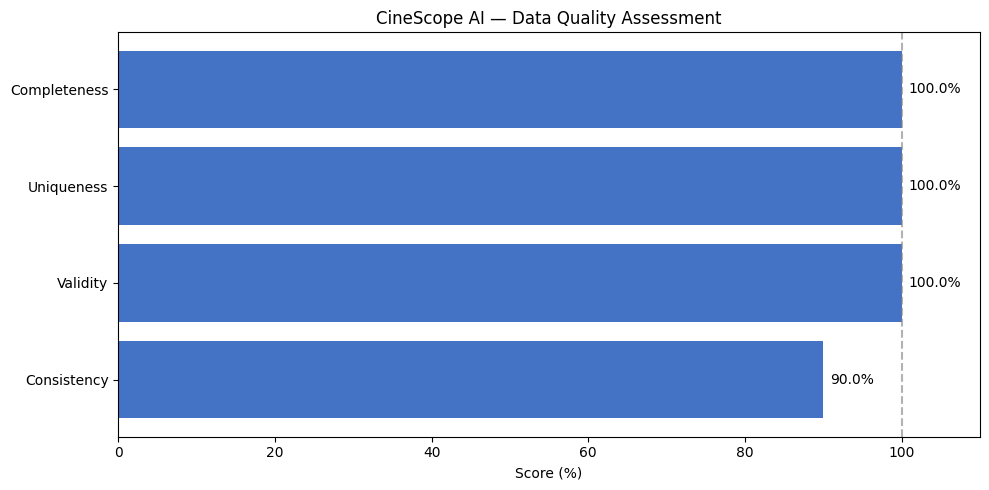

In [11]:

# Generate consolidated data quality scorecard

data_quality_scorecard = pd.DataFrame({
    "Dimension": [
        "Completeness",
        "Uniqueness",
        "Validity",
        "Consistency",
        "Accuracy",
        "Timeliness"
    ],
    "Score (%)": [
        overall_completeness,
        uniqueness_score,
        overall_validity,
        overall_consistency,
        np.nan,
        np.nan
    ],
    "Assessment Status": [
        "Assessed",
        "Assessed",
        "Assessed",
        "Assessed",
        "Pending External Verification",
        "Pending Reporting Date Verification"
    ]
})

# Calculate composite score using assessed dimensions

composite_quality_score = (
    data_quality_scorecard["Score (%)"].mean()
)

# Display scorecard

print("CineScope AI — Data Quality Scorecard")
print("=" * 50)

display(data_quality_scorecard)

print(f"\nComposite Diagnostic Score: "
      f"{composite_quality_score:.2f}%")

dimensions_assessed = (
    data_quality_scorecard["Score (%)"].notna().sum()
)

total_dimensions = len(data_quality_scorecard)

print(
    f"Dimensions Assessed: "
    f"{dimensions_assessed} of {total_dimensions}"
)

print("\nNote: Accuracy and timeliness are excluded "
      "from the composite score.")

# Visualize assessed data quality dimensions

assessed_dimensions = data_quality_scorecard.dropna(
    subset=["Score (%)"]
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    assessed_dimensions["Dimension"],
    assessed_dimensions["Score (%)"],
    color="#4472C4"
)

ax.set_xlim(0, 110)
ax.set_xlabel("Score (%)")
ax.set_title("CineScope AI — Data Quality Assessment")

ax.invert_yaxis()

ax.axvline(
    x=100,
    color="gray",
    linestyle="--",
    alpha=0.6
)

ax.bar_label(
    bars,
    fmt="%.1f%%",
    padding=5
)

plt.tight_layout()
plt.show()


## 5. Data Quality Findings & Remediation Recommendations

This section consolidates identified data quality exceptions,
structural limitations, and verification gaps into a formal
Data Quality Issue Register (DQIR).

The objectives of this section are to:

- Document identified data quality issues and limitations.
- Establish traceability between audit findings and business rules.
- Evaluate potential downstream business and analytical impacts.
- Prioritize issues according to severity.
- Recommend appropriate remediation strategies.
- Assess dataset readiness for subsequent development phases.

All findings are documented without modifying the original
source dataset. Remediation activities will be performed
during the subsequent data cleaning and preparation phase.

### 5.1 Data Quality Issue Register

The Data Quality Issue Register serves as a centralized record
of exceptions, structural limitations, and unresolved
verification requirements identified during the data audit.

Each issue is assigned a unique identifier to support
traceability throughout the CineScope AI development lifecycle.

The register distinguishes between confirmed data quality
exceptions, preprocessing requirements, verification gaps,
and limitations affecting analytical fitness for purpose.

In [12]:
# Initialize the Data Quality Issue Register

data_quality_issues = [
    {
        "Issue ID": "DQ-001",
        "Issue Category": "Consistency",
        "Issue Description": (
            "Recorded rankings do not correspond to "
            "descending worldwide gross."
        ),
        "Audit Reference": "Section 4.4 / DQ-BR-002",
        "Affected Records": rank_violations,
        "Finding Type": "Confirmed Exception",
        "Status": "Open"
    },
    {
        "Issue ID": "DQ-002",
        "Issue Category": "Data Type",
        "Issue Description": (
            "Financial attributes are stored as strings "
            "containing currency formatting."
        ),
        "Audit Reference": "Schema Assessment",
        "Affected Records": len(df_raw),
        "Finding Type": "Preprocessing Requirement",
        "Status": "Open"
    },
    {
        "Issue ID": "DQ-003",
        "Issue Category": "Data Type",
        "Issue Description": (
            "Release dates require conversion to "
            "datetime format."
        ),
        "Audit Reference": "Schema Assessment",
        "Affected Records": len(df_raw),
        "Finding Type": "Preprocessing Requirement",
        "Status": "Open"
    },
    {
        "Issue ID": "DQ-004",
        "Issue Category": "Accuracy",
        "Issue Description": (
            "Source values have not been independently "
            "verified against authoritative sources."
        ),
        "Audit Reference": "Section 4.5",
        "Affected Records": len(df_raw),
        "Finding Type": "Verification Gap",
        "Status": "Pending Verification"
    },
    {
        "Issue ID": "DQ-005",
        "Issue Category": "Timeliness",
        "Issue Description": (
            "Dataset reporting date and revenue "
            "collection period have not been established."
        ),
        "Audit Reference": "Section 4.5",
        "Affected Records": len(df_raw),
        "Finding Type": "Verification Gap",
        "Status": "Pending Verification"
    },
    {
        "Issue ID": "DQ-006",
        "Issue Category": "Fitness for Purpose",
        "Issue Description": (
            "Limited record volume and feature coverage "
            "restrict predictive modeling capabilities."
        ),
        "Audit Reference": "Dataset Profiling",
        "Affected Records": len(df_raw),
        "Finding Type": "Dataset Limitation",
        "Status": "Open"
    }
]

# Convert issue register into a structured DataFrame

issue_register = pd.DataFrame(data_quality_issues)

# Display the Data Quality Issue Register

print("CineScope AI — Data Quality Issue Register")
print("=" * 50)

display(issue_register)

# Summarize identified findings

print(f"\nTotal Findings: {len(issue_register)}")

print("\nFindings by Type:")

display(
    issue_register["Finding Type"]
    .value_counts()
    .rename_axis("Finding Type")
    .reset_index(name="Count")
)

print("\nFindings by Status:")

display(
    issue_register["Status"]
    .value_counts()
    .rename_axis("Status")
    .reset_index(name="Count")
)

CineScope AI — Data Quality Issue Register


,Issue ID,Issue Category,Issue Description,Audit Reference,Affected Records,Finding Type,Status
0,DQ-001,Consistency,Recorded rankings do not correspond to descend...,Section 4.4 / DQ-BR-002,2,Confirmed Exception,Open
1,DQ-002,Data Type,Financial attributes are stored as strings con...,Schema Assessment,10,Preprocessing Requirement,Open
2,DQ-003,Data Type,Release dates require conversion to datetime f...,Schema Assessment,10,Preprocessing Requirement,Open
3,DQ-004,Accuracy,Source values have not been independently veri...,Section 4.5,10,Verification Gap,Pending Verification
4,DQ-005,Timeliness,Dataset reporting date and revenue collection ...,Section 4.5,10,Verification Gap,Pending Verification
5,DQ-006,Fitness for Purpose,Limited record volume and feature coverage res...,Dataset Profiling,10,Dataset Limitation,Open



Total Findings: 6

Findings by Type:


,Finding Type,Count
0,Preprocessing Requirement,2
1,Verification Gap,2
2,Confirmed Exception,1
3,Dataset Limitation,1



Findings by Status:


,Status,Count
0,Open,4
1,Pending Verification,2


### 5.2 Issue Severity and Prioritization

Each identified data quality finding is evaluated according
to its potential impact on the intended analytical,
financial, and predictive capabilities of CineScope AI.

Severity represents the magnitude of the potential impact
associated with an issue, while priority represents the
urgency and relative order in which remediation should
be addressed.

#### Severity Classification Framework

| Severity | Classification | Definition |
|---|---|---|
| SEV-1 | Critical | Prevents reliable delivery of a core product capability or creates an unacceptable risk of misleading outputs. |
| SEV-2 | High | Materially affects analytical reliability, business interpretation, or essential data processing. |
| SEV-3 | Medium | Affects specific analytical capabilities but can be managed through controlled preprocessing or mitigation. |
| SEV-4 | Low | Represents a minor issue with limited impact on core functionality. |

#### Priority Classification Framework

| Priority | Classification | Definition |
|---|---|---|
| P1 | Critical Priority | Must be addressed before the affected core capability can be considered ready. |
| P2 | High Priority | Must be addressed before dependent analytical functionality is used. |
| P3 | Medium Priority | Address during the appropriate data preparation phase. |
| P4 | Low Priority | Address through routine maintenance or future enhancement. |

Severity and priority assignments are based on documented
business requirements, downstream analytical dependencies,
and potential risks to product reliability.

The classifications represent project-specific analytical
judgment and may be revised as additional information
becomes available.

Critical findings do not necessarily prevent controlled
data preparation activities from proceeding. However,
they establish readiness constraints for the affected
product capabilities.

In [13]:
# Define severity and priority assessments

issue_assessments = [
    {
        "Issue ID": "DQ-001",
        "Severity": "High",
        "Severity Code": "SEV-2",
        "Priority": "P2",
        "Business Impact": (
            "Incorrect film rankings may misrepresent "
            "relative box office performance."
        ),
        "Affected Capability": "Market Intelligence"
    },
    {
        "Issue ID": "DQ-002",
        "Severity": "High",
        "Severity Code": "SEV-2",
        "Priority": "P2",
        "Business Impact": (
            "String-based financial attributes prevent "
            "direct numerical aggregation and calculation."
        ),
        "Affected Capability": (
            "Market Intelligence / Financial Analytics"
        )
    },
    {
        "Issue ID": "DQ-003",
        "Severity": "Medium",
        "Severity Code": "SEV-3",
        "Priority": "P3",
        "Business Impact": (
            "Unconverted release dates restrict temporal "
            "analysis and date-based feature engineering."
        ),
        "Affected Capability": (
            "Temporal Analytics / Feature Engineering"
        )
    },
    {
        "Issue ID": "DQ-004",
        "Severity": "Critical",
        "Severity Code": "SEV-1",
        "Priority": "P1",
        "Business Impact": (
            "Unverified source values may produce "
            "misleading analytical insights and unreliable "
            "model evaluation results."
        ),
        "Affected Capability": (
            "Market Intelligence / Model Evaluation / AI Copilot"
        )
    },
    {
        "Issue ID": "DQ-005",
        "Severity": "High",
        "Severity Code": "SEV-2",
        "Priority": "P2",
        "Business Impact": (
            "An unknown reporting period limits revenue "
            "comparability and confidence in data freshness."
        ),
        "Affected Capability": "Market Intelligence"
    },
    {
        "Issue ID": "DQ-006",
        "Severity": "Critical",
        "Severity Code": "SEV-1",
        "Priority": "P1",
        "Business Impact": (
            "Insufficient historical observations and "
            "predictive features prevent reliable model "
            "training and generalization."
        ),
        "Affected Capability": "Box Office Prediction"
    }
]

# Convert assessments into a structured DataFrame

severity_assessment = pd.DataFrame(issue_assessments)

# Validate issue identifier coverage

if set(issue_register["Issue ID"]) != set(
    severity_assessment["Issue ID"]
):
    raise ValueError(
        "Severity assessment does not cover all registered issues."
    )

# Integrate assessments with the original issue register

prioritized_issue_register = issue_register.merge(
    severity_assessment,
    on="Issue ID",
    how="left",
    validate="one_to_one"
)

# Define ordered severity classifications

severity_order = [
    "Critical",
    "High",
    "Medium",
    "Low"
]

prioritized_issue_register["Severity"] = pd.Categorical(
    prioritized_issue_register["Severity"],
    categories=severity_order,
    ordered=True
)

# Sort findings by priority, severity, and issue identifier

prioritized_issue_register = (
    prioritized_issue_register
    .sort_values(
        by=["Priority", "Severity", "Issue ID"]
    )
    .reset_index(drop=True)
)

# Display prioritized findings

print("CineScope AI — Issue Severity and Prioritization")
print("=" * 50)

display(
    prioritized_issue_register[
        [
            "Issue ID",
            "Issue Category",
            "Severity",
            "Severity Code",
            "Priority",
            "Business Impact",
            "Affected Capability",
            "Status"
        ]
    ]
)

# Generate severity distribution

severity_summary = (
    prioritized_issue_register["Severity"]
    .value_counts(sort=False)
    .rename_axis("Severity")
    .reset_index(name="Count")
)

print("\nFindings by Severity:")

display(severity_summary)

# Generate priority distribution

priority_summary = (
    prioritized_issue_register["Priority"]
    .value_counts()
    .reindex(["P1", "P2", "P3", "P4"], fill_value=0)
    .rename_axis("Priority")
    .reset_index(name="Count")
)

print("\nFindings by Priority:")

display(priority_summary)

# Identify critical findings

critical_issues = prioritized_issue_register[
    prioritized_issue_register["Severity"] == "Critical"
]

print(f"\nTotal Critical Findings: {len(critical_issues)}")

print("\nCritical Findings Requiring Resolution:")

display(
    critical_issues[
        [
            "Issue ID",
            "Issue Description",
            "Affected Capability",
            "Status"
        ]
    ]
)

CineScope AI — Issue Severity and Prioritization


,Issue ID,Issue Category,Severity,Severity Code,Priority,Business Impact,Affected Capability,Status
0,DQ-004,Accuracy,Critical,SEV-1,P1,Unverified source values may produce misleadin...,Market Intelligence / Model Evaluation / AI Co...,Pending Verification
1,DQ-006,Fitness for Purpose,Critical,SEV-1,P1,Insufficient historical observations and predi...,Box Office Prediction,Open
2,DQ-001,Consistency,High,SEV-2,P2,Incorrect film rankings may misrepresent relat...,Market Intelligence,Open
3,DQ-002,Data Type,High,SEV-2,P2,String-based financial attributes prevent dire...,Market Intelligence / Financial Analytics,Open
4,DQ-005,Timeliness,High,SEV-2,P2,An unknown reporting period limits revenue com...,Market Intelligence,Pending Verification
5,DQ-003,Data Type,Medium,SEV-3,P3,Unconverted release dates restrict temporal an...,Temporal Analytics / Feature Engineering,Open



Findings by Severity:


,Severity,Count
0,Critical,2
1,High,3
2,Medium,1
3,Low,0



Findings by Priority:


,Priority,Count
0,P1,2
1,P2,3
2,P3,1
3,P4,0



Total Critical Findings: 2

Critical Findings Requiring Resolution:


,Issue ID,Issue Description,Affected Capability,Status
0,DQ-004,Source values have not been independently veri...,Market Intelligence / Model Evaluation / AI Co...,Pending Verification
1,DQ-006,Limited record volume and feature coverage res...,Box Office Prediction,Open


### 5.3 Remediation Strategy

This subsection establishes corrective actions,
acceptance criteria, and resolution requirements for
each finding documented in the Data Quality Issue
Register.

The remediation strategy is designed to address
identified data quality exceptions, preprocessing
requirements, verification gaps, and limitations
affecting analytical fitness for purpose.

#### Remediation Objectives

- Establish actionable corrective measures for each
  identified finding.
- Define measurable acceptance criteria for successful
  remediation.
- Identify appropriate remediation methods and
  development phases.
- Establish traceability between audit findings,
  corrective actions, and validation evidence.
- Preserve the integrity of the original source dataset.
- Prevent unresolved findings from compromising
  downstream analytical and predictive capabilities.

#### Remediation Method Classification

| Method | Description |
|---|---|
| Programmatic Remediation | Corrective actions implemented through controlled data transformation, standardization, and validation procedures. |
| External Verification | Independent validation of source attributes, provenance, reporting periods, and associated metadata. |
| Dataset Expansion | Acquisition and qualification of additional observations and predictive features to satisfy analytical requirements. |

#### Remediation Principles

All programmatic transformations will be performed
on a separate working copy of the source dataset.

External verification findings will remain unresolved
until sufficient supporting evidence has been obtained.

Dataset limitations will be addressed through additional
data acquisition and qualification rather than through
unsupported assumptions or artificial record generation.

Acceptance criteria must be satisfied and supporting
resolution evidence documented before a finding can
be classified as resolved.

The remediation plan represents a proposed set of
corrective actions. No source data modifications or
issue resolutions are performed within this subsection.

In [14]:
# Define remediation strategies and acceptance criteria

remediation_actions = [
    {
        "Issue ID": "DQ-001",
        "Remediation Strategy": (
            "Recalculate film rankings based on descending "
            "worldwide gross after financial data conversion. "
            "Preserve original rankings for traceability."
        ),
        "Remediation Method": "Programmatic Remediation",
        "Acceptance Criteria": (
            "All calculated rankings correspond to descending "
            "worldwide gross within the supplied dataset. "
            "Any ties follow a documented ranking policy. "
            "Zero ranking consistency violations remain."
        ),
        "Target Phase": "Data Cleaning",
        "Resolution Evidence": (
            "Before-and-after ranking comparison and "
            "successful execution of DQ-BR-002."
        )
    },
    {
        "Issue ID": "DQ-002",
        "Remediation Strategy": (
            "Remove currency formatting and convert worldwide "
            "and domestic gross attributes into numeric values."
        ),
        "Remediation Method": "Programmatic Remediation",
        "Acceptance Criteria": (
            "Both financial attributes have numeric data types. "
            "All original monetary magnitudes are preserved. "
            "Zero conversion failures, unintended missing "
            "values, or negative revenue values remain."
        ),
        "Target Phase": "Data Cleaning",
        "Resolution Evidence": (
            "Data type validation, monetary value "
            "reconciliation, and conversion exception report."
        )
    },
    {
        "Issue ID": "DQ-003",
        "Remediation Strategy": (
            "Convert release date attributes into a "
            "standardized datetime representation."
        ),
        "Remediation Method": "Programmatic Remediation",
        "Acceptance Criteria": (
            "The release date attribute has a datetime "
            "data type. All source dates are successfully "
            "parsed with zero conversion failures or "
            "unintended missing values."
        ),
        "Target Phase": "Data Cleaning",
        "Resolution Evidence": (
            "Data type validation and date conversion "
            "exception report."
        )
    },
    {
        "Issue ID": "DQ-004",
        "Remediation Strategy": (
            "Independently verify film titles, release dates, "
            "distributors, revenue figures, and currency "
            "against reliable external sources."
        ),
        "Remediation Method": "External Verification",
        "Acceptance Criteria": (
            "All records intended for factual analytical use "
            "have documented supporting sources. Material "
            "discrepancies are reconciled or affected records "
            "are excluded from verified analytical outputs."
        ),
        "Target Phase": "Data Verification",
        "Resolution Evidence": (
            "Record-level source verification log, source URLs, "
            "access dates, and discrepancy reconciliation report."
        )
    },
    {
        "Issue ID": "DQ-005",
        "Remediation Strategy": (
            "Establish the dataset reporting date, revenue "
            "collection period, and revenue measurement scope."
        ),
        "Remediation Method": "External Verification",
        "Acceptance Criteria": (
            "The reporting date and revenue measurement scope "
            "are supported by documented evidence. Revenue "
            "figures used in comparisons have compatible "
            "measurement periods or disclosed limitations."
        ),
        "Target Phase": "Data Verification",
        "Resolution Evidence": (
            "Documented reporting metadata and supporting "
            "source references."
        )
    },
    {
        "Issue ID": "DQ-006",
        "Remediation Strategy": (
            "Acquire a larger historical movie dataset "
            "containing relevant pre-release predictive "
            "features and verified revenue outcomes."
        ),
        "Remediation Method": "Dataset Expansion",
        "Acceptance Criteria": (
            "A historical dataset satisfies documented "
            "sample size, feature coverage, target quality, "
            "and temporal coverage requirements. The dataset "
            "supports chronological training and evaluation "
            "without post-release feature leakage."
        ),
        "Target Phase": "Data Acquisition",
        "Resolution Evidence": (
            "Historical dataset audit, feature availability "
            "assessment, data dictionary, and documented "
            "training and evaluation design."
        )
    }
]

# Convert remediation actions into a structured DataFrame

remediation_assessment = pd.DataFrame(remediation_actions)

# Validate issue identifier coverage

if set(prioritized_issue_register["Issue ID"]) != set(
    remediation_assessment["Issue ID"]
):
    raise ValueError(
        "Remediation assessment does not cover "
        "all registered issues."
    )

# Integrate remediation actions with prioritized findings

remediation_register = prioritized_issue_register.merge(
    remediation_assessment,
    on="Issue ID",
    how="left",
    validate="one_to_one"
)

# Define required remediation attributes

required_remediation_fields = [
    "Remediation Strategy",
    "Remediation Method",
    "Acceptance Criteria",
    "Target Phase",
    "Resolution Evidence"
]

# Validate remediation documentation completeness

remediation_fields = remediation_register[
    required_remediation_fields
]

missing_fields = (
    remediation_fields.isna()
    | remediation_fields.apply(
        lambda column: column.astype(str).str.strip().eq("")
    )
)

if missing_fields.any().any():
    raise ValueError(
        "One or more required remediation attributes "
        "are missing or empty."
    )

# Display remediation strategy

print("CineScope AI — Remediation Strategy")
print("=" * 50)

with pd.option_context("display.max_colwidth", None):
    display(
        remediation_register[
            [
                "Issue ID",
                "Severity",
                "Priority",
                "Remediation Strategy",
                "Remediation Method",
                "Target Phase",
                "Status"
            ]
        ]
    )

# Display acceptance criteria and evidence requirements

print("\nAcceptance Criteria and Resolution Evidence:")

with pd.option_context("display.max_colwidth", None):
    display(
        remediation_register[
            [
                "Issue ID",
                "Acceptance Criteria",
                "Resolution Evidence"
            ]
        ]
    )

# Summarize findings by remediation method

remediation_method_summary = (
    remediation_register["Remediation Method"]
    .value_counts()
    .rename_axis("Remediation Method")
    .reset_index(name="Count")
)

print("\nFindings by Remediation Method:")

display(remediation_method_summary)

# Summarize findings by target phase

remediation_phase_summary = (
    remediation_register["Target Phase"]
    .value_counts()
    .rename_axis("Target Phase")
    .reset_index(name="Count")
)

print("\nFindings by Target Phase:")

display(remediation_phase_summary)

# Calculate remediation planning coverage

planned_findings = (~missing_fields.any(axis=1)).sum()

remediation_coverage = (
    planned_findings / len(prioritized_issue_register)
) * 100

print(f"\nTotal Findings: {len(prioritized_issue_register)}")
print(f"Findings with Remediation Plans: {planned_findings}")
print(f"Remediation Planning Coverage: {remediation_coverage:.2f}%")

print(
    "\nNote: Remediation planning does not indicate "
    "that any finding has been resolved."
)

CineScope AI — Remediation Strategy


,Issue ID,Severity,Priority,Remediation Strategy,Remediation Method,Target Phase,Status
0,DQ-004,Critical,P1,"Independently verify film titles, release dates, distributors, revenue figures, and currency against reliable external sources.",External Verification,Data Verification,Pending Verification
1,DQ-006,Critical,P1,Acquire a larger historical movie dataset containing relevant pre-release predictive features and verified revenue outcomes.,Dataset Expansion,Data Acquisition,Open
2,DQ-001,High,P2,Recalculate film rankings based on descending worldwide gross after financial data conversion. Preserve original rankings for traceability.,Programmatic Remediation,Data Cleaning,Open
3,DQ-002,High,P2,Remove currency formatting and convert worldwide and domestic gross attributes into numeric values.,Programmatic Remediation,Data Cleaning,Open
4,DQ-005,High,P2,"Establish the dataset reporting date, revenue collection period, and revenue measurement scope.",External Verification,Data Verification,Pending Verification
5,DQ-003,Medium,P3,Convert release date attributes into a standardized datetime representation.,Programmatic Remediation,Data Cleaning,Open



Acceptance Criteria and Resolution Evidence:


,Issue ID,Acceptance Criteria,Resolution Evidence
0,DQ-004,All records intended for factual analytical use have documented supporting sources. Material discrepancies are reconciled or affected records are excluded from verified analytical outputs.,"Record-level source verification log, source URLs, access dates, and discrepancy reconciliation report."
1,DQ-006,"A historical dataset satisfies documented sample size, feature coverage, target quality, and temporal coverage requirements. The dataset supports chronological training and evaluation without post-release feature leakage.","Historical dataset audit, feature availability assessment, data dictionary, and documented training and evaluation design."
2,DQ-001,All calculated rankings correspond to descending worldwide gross within the supplied dataset. Any ties follow a documented ranking policy. Zero ranking consistency violations remain.,Before-and-after ranking comparison and successful execution of DQ-BR-002.
3,DQ-002,"Both financial attributes have numeric data types. All original monetary magnitudes are preserved. Zero conversion failures, unintended missing values, or negative revenue values remain.","Data type validation, monetary value reconciliation, and conversion exception report."
4,DQ-005,The reporting date and revenue measurement scope are supported by documented evidence. Revenue figures used in comparisons have compatible measurement periods or disclosed limitations.,Documented reporting metadata and supporting source references.
5,DQ-003,The release date attribute has a datetime data type. All source dates are successfully parsed with zero conversion failures or unintended missing values.,Data type validation and date conversion exception report.



Findings by Remediation Method:


,Remediation Method,Count
0,Programmatic Remediation,3
1,External Verification,2
2,Dataset Expansion,1



Findings by Target Phase:


,Target Phase,Count
0,Data Cleaning,3
1,Data Verification,2
2,Data Acquisition,1



Total Findings: 6
Findings with Remediation Plans: 6
Remediation Planning Coverage: 100.00%

Note: Remediation planning does not indicate that any finding has been resolved.



### 5.4 Issue Resolution Tracking

This subsection establishes a structured issue resolution tracking framework for monitoring the execution, validation, resolution, and formal closure of findings documented in the Data Quality Issue Register.

The framework maintains traceability between identified findings, remediation strategies, acceptance criteria, validation outcomes, and supporting resolution evidence throughout the CineScope AI development lifecycle.

#### Issue Resolution Tracking Objectives

- Establish a standardized lifecycle for managing data quality findings.
- Preserve traceability between audit findings and subsequent corrective actions.
- Monitor remediation execution and validation progress.
- Establish controlled requirements for issue resolution and formal closure.
- Document actual resolution evidence and validation outcomes.
- Prevent premature issue resolution or closure.
- Maintain measurable indicators of remediation and resolution progress.

#### Issue Lifecycle Status Definitions

| Status | Definition |
|---|---|
| Open | The finding has been identified and documented, but corrective action has not commenced. |
| Pending Verification | The finding requires external evidence before factual accuracy or resolution can be established. |
| In Progress | Corrective action or supporting evidence collection is underway. |
| Pending Validation | Corrective action has been implemented and is awaiting validation against documented acceptance criteria. |
| Resolved | Documented acceptance criteria have been satisfied and supporting resolution evidence has been recorded. |
| Closed | Resolution evidence has been reviewed and the finding has been formally closed. |

#### Permissible Status Transitions

| Current Status | Permitted Subsequent Status |
|---|---|
| Open | In Progress, Pending Verification |
| Pending Verification | In Progress |
| In Progress | Pending Validation, Pending Verification |
| Pending Validation | Resolved, In Progress |
| Resolved | Closed, In Progress |
| Closed | Open |

Status transitions must reflect actual remediation activities and documented validation outcomes.

Findings that fail acceptance criteria validation must return to an active remediation status.

Previously resolved or closed findings may be reopened if subsequent evidence identifies recurring exceptions, incomplete remediation, or invalidated assumptions.

#### Resolution Tracking Attributes

| Attribute | Description |
|---|---|
| Issue ID | Unique identifier linking the finding to the Data Quality Issue Register. |
| Status | Current lifecycle status of the finding. |
| Remediation Start Date | Date on which corrective action or evidence collection commenced. |
| Remediation Completion Date | Date on which corrective action was implemented. |
| Validation Status | Current outcome of acceptance criteria validation. |
| Validation Date | Date on which remediation validation was performed. |
| Actual Resolution Evidence | Supporting evidence demonstrating the outcome of corrective action and validation. |
| Resolution Date | Date on which the finding satisfied its documented acceptance criteria. |
| Closure Date | Date on which the finding was formally closed. |
| Closure Notes | Documentation supporting the formal closure decision. |
| Tracking Notes | Additional information concerning remediation progress, dependencies, or outstanding requirements. |

#### Validation Status Definitions

| Validation Status | Definition |
|---|---|
| Not Started | Acceptance criteria validation has not commenced. |
| In Progress | Acceptance criteria validation is underway. |
| Passed | All applicable acceptance criteria have been satisfied. |
| Failed | One or more applicable acceptance criteria have not been satisfied. |

#### Issue Resolution and Closure Criteria

A finding may be classified as Resolved only when:

- The documented remediation strategy has been implemented.
- All applicable acceptance criteria have been satisfied.
- The validation status is recorded as Passed.
- Actual resolution evidence has been documented.
- The remediation completion, validation, and resolution dates have been recorded.

A finding may be classified as Closed only when:

- All issue resolution criteria have been satisfied.
- Supporting resolution evidence has been reviewed.
- The closure date and closure notes have been documented.

#### Resolution Progress Metrics

The following indicators will be maintained to monitor issue resolution progress:

- Total registered findings.
- Open findings.
- Findings pending external verification.
- Findings in progress.
- Findings pending validation.
- Resolved findings.
- Closed findings.
- Outstanding findings.
- Issue resolution rate.
- Issue closure rate.

The issue resolution rate represents the percentage of registered findings classified as Resolved or Closed.

The issue closure rate represents the percentage of registered findings classified as Closed.

#### Initial Tracking Baseline

All findings retain their existing lifecycle statuses upon initialization of the resolution tracking register.

Remediation execution dates, validation dates, actual resolution evidence, resolution dates, and closure information remain unpopulated until the corresponding activities have been performed and documented.

The resolution tracking register represents the initial issue management baseline for subsequent development phases.

No corrective actions, external verification activities, acceptance criteria validations, or issue closures are performed within this subsection.


In [15]:

# Initialize the issue resolution tracking register

resolution_tracking_register = remediation_register.copy(deep=True)


# Define permissible issue lifecycle statuses

valid_issue_statuses = [
    "Open",
    "Pending Verification",
    "In Progress",
    "Pending Validation",
    "Resolved",
    "Closed"
]


# Define permissible status transitions

allowed_status_transitions = {
    "Open": [
        "In Progress",
        "Pending Verification"
    ],
    "Pending Verification": [
        "In Progress"
    ],
    "In Progress": [
        "Pending Validation",
        "Pending Verification"
    ],
    "Pending Validation": [
        "Resolved",
        "In Progress"
    ],
    "Resolved": [
        "Closed",
        "In Progress"
    ],
    "Closed": [
        "Open"
    ]
}


# Define permissible validation statuses

valid_validation_statuses = [
    "Not Started",
    "In Progress",
    "Passed",
    "Failed"
]


# Initialize remediation and resolution tracking attributes

tracking_date_fields = [
    "Remediation Start Date",
    "Remediation Completion Date",
    "Validation Date",
    "Resolution Date",
    "Closure Date"
]

for field in tracking_date_fields:
    resolution_tracking_register[field] = pd.Series(
        pd.NaT,
        index=resolution_tracking_register.index,
        dtype="datetime64[ns]"
    )

resolution_tracking_register["Validation Status"] = "Not Started"

resolution_tracking_register["Actual Resolution Evidence"] = pd.NA

resolution_tracking_register["Closure Notes"] = pd.NA

resolution_tracking_register["Tracking Notes"] = (
    "Awaiting remediation execution."
)


# Document external verification dependencies

pending_verification_mask = (
    resolution_tracking_register["Status"]
    .eq("Pending Verification")
)

resolution_tracking_register.loc[
    pending_verification_mask,
    "Tracking Notes"
] = "Awaiting supporting external verification evidence."


# Validate issue identifier integrity

if resolution_tracking_register["Issue ID"].isna().any():
    raise ValueError(
        "Missing issue identifiers detected."
    )

if resolution_tracking_register["Issue ID"].duplicated().any():
    raise ValueError(
        "Duplicate issue identifiers detected."
    )

if set(resolution_tracking_register["Issue ID"]) != set(
    remediation_register["Issue ID"]
):
    raise ValueError(
        "Resolution tracking register does not preserve "
        "all registered findings."
    )


# Validate issue lifecycle statuses

if not resolution_tracking_register["Status"].isin(
    valid_issue_statuses
).all():
    raise ValueError(
        "Invalid issue lifecycle status detected."
    )


# Validate acceptance criteria validation statuses

if not resolution_tracking_register["Validation Status"].isin(
    valid_validation_statuses
).all():
    raise ValueError(
        "Invalid validation status detected."
    )


# Validate preservation of existing issue statuses

original_statuses = (
    remediation_register
    .set_index("Issue ID")["Status"]
    .sort_index()
)

tracking_statuses = (
    resolution_tracking_register
    .set_index("Issue ID")["Status"]
    .sort_index()
)

if not original_statuses.equals(tracking_statuses):
    raise ValueError(
        "Existing issue statuses were modified "
        "during tracking initialization."
    )


# Validate resolution requirements

resolved_or_closed_mask = (
    resolution_tracking_register["Status"]
    .isin(["Resolved", "Closed"])
)

resolution_required_fields = [
    "Remediation Start Date",
    "Remediation Completion Date",
    "Validation Date",
    "Actual Resolution Evidence",
    "Resolution Date"
]

resolved_findings = resolution_tracking_register.loc[
    resolved_or_closed_mask
]

if not resolved_findings["Validation Status"].eq("Passed").all():
    raise ValueError(
        "Resolved or closed findings must have "
        "a Passed validation status."
    )

resolution_fields = resolved_findings[
    resolution_required_fields
]


missing_resolution_fields = resolution_fields.isna()

for column in resolution_fields.columns:
    missing_resolution_fields[column] = (
        missing_resolution_fields[column]
        | resolution_fields[column]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
    )


if missing_resolution_fields.any().any():
    raise ValueError(
        "Resolved or closed findings contain "
        "incomplete resolution documentation."
    )


# Validate formal closure requirements

closed_mask = (
    resolution_tracking_register["Status"]
    .eq("Closed")
)

closed_findings = resolution_tracking_register.loc[
    closed_mask
]

closure_fields = closed_findings[
    ["Closure Date", "Closure Notes"]
]


missing_closure_fields = closure_fields.isna()

for column in closure_fields.columns:
    missing_closure_fields[column] = (
        missing_closure_fields[column]
        | closure_fields[column]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
    )


if missing_closure_fields.any().any():
    raise ValueError(
        "Closed findings contain incomplete "
        "closure documentation."
    )


# Validate initial tracking baseline

if resolved_or_closed_mask.any():
    raise ValueError(
        "The initial tracking baseline must not contain "
        "resolved or closed findings."
    )

if resolution_tracking_register[
    tracking_date_fields
].notna().any().any():
    raise ValueError(
        "Tracking dates must remain unpopulated "
        "during baseline initialization."
    )

if not resolution_tracking_register[
    "Validation Status"
].eq("Not Started").all():
    raise ValueError(
        "Validation must not commence during "
        "tracking initialization."
    )


# Display the issue resolution tracking register

print("CineScope AI - Issue Resolution Tracking")
print("=" * 50)

with pd.option_context("display.max_colwidth", None):
    display(
        resolution_tracking_register[
            [
                "Issue ID",
                "Severity",
                "Priority",
                "Remediation Method",
                "Target Phase",
                "Status",
                "Validation Status",
                "Tracking Notes"
            ]
        ]
    )


# Display remediation execution and validation attributes

print("\nRemediation Execution and Validation Tracking:")

display(
    resolution_tracking_register[
        [
            "Issue ID",
            "Remediation Start Date",
            "Remediation Completion Date",
            "Validation Status",
            "Validation Date"
        ]
    ]
)


# Display resolution and closure attributes

print("\nResolution and Closure Tracking:")

display(
    resolution_tracking_register[
        [
            "Issue ID",
            "Actual Resolution Evidence",
            "Resolution Date",
            "Closure Date",
            "Closure Notes"
        ]
    ]
)


# Summarize findings by lifecycle status

resolution_status_summary = (
    resolution_tracking_register["Status"]
    .value_counts()
    .reindex(valid_issue_statuses, fill_value=0)
    .rename_axis("Status")
    .reset_index(name="Count")
)

print("\nFindings by Lifecycle Status:")

display(resolution_status_summary)


# Summarize findings by validation status

validation_status_summary = (
    resolution_tracking_register["Validation Status"]
    .value_counts()
    .reindex(valid_validation_statuses, fill_value=0)
    .rename_axis("Validation Status")
    .reset_index(name="Count")
)

print("\nFindings by Validation Status:")

display(validation_status_summary)


# Calculate issue resolution progress metrics

total_findings = len(resolution_tracking_register)

resolved_findings_count = (
    resolution_tracking_register["Status"]
    .eq("Resolved")
    .sum()
)

closed_findings_count = (
    resolution_tracking_register["Status"]
    .eq("Closed")
    .sum()
)

successfully_resolved_findings = (
    resolved_findings_count + closed_findings_count
)

outstanding_findings = (
    total_findings - successfully_resolved_findings
)

issue_resolution_rate = (
    successfully_resolved_findings / total_findings * 100
    if total_findings > 0
    else 0.0
)

issue_closure_rate = (
    closed_findings_count / total_findings * 100
    if total_findings > 0
    else 0.0
)


# Display resolution progress metrics

print("\nIssue Resolution Progress:")
print("=" * 50)

print(f"Total Registered Findings: {total_findings}")
print(f"Resolved Findings: {resolved_findings_count}")
print(f"Closed Findings: {closed_findings_count}")
print(f"Outstanding Findings: {outstanding_findings}")
print(f"Issue Resolution Rate: {issue_resolution_rate:.2f}%")
print(f"Issue Closure Rate: {issue_closure_rate:.2f}%")


# Confirm successful baseline initialization

print(
    "\nValidation Result: Issue resolution tracking "
    "baseline successfully initialized."
)

print(
    "\nNote: Tracking initialization does not indicate "
    "that any remediation, verification, validation, "
    "resolution, or closure activity has been performed."
)


CineScope AI - Issue Resolution Tracking


,Issue ID,Severity,Priority,Remediation Method,Target Phase,Status,Validation Status,Tracking Notes
0,DQ-004,Critical,P1,External Verification,Data Verification,Pending Verification,Not Started,Awaiting supporting external verification evidence.
1,DQ-006,Critical,P1,Dataset Expansion,Data Acquisition,Open,Not Started,Awaiting remediation execution.
2,DQ-001,High,P2,Programmatic Remediation,Data Cleaning,Open,Not Started,Awaiting remediation execution.
3,DQ-002,High,P2,Programmatic Remediation,Data Cleaning,Open,Not Started,Awaiting remediation execution.
4,DQ-005,High,P2,External Verification,Data Verification,Pending Verification,Not Started,Awaiting supporting external verification evidence.
5,DQ-003,Medium,P3,Programmatic Remediation,Data Cleaning,Open,Not Started,Awaiting remediation execution.



Remediation Execution and Validation Tracking:


,Issue ID,Remediation Start Date,Remediation Completion Date,Validation Status,Validation Date
0,DQ-004,NaT,NaT,Not Started,NaT
1,DQ-006,NaT,NaT,Not Started,NaT
2,DQ-001,NaT,NaT,Not Started,NaT
3,DQ-002,NaT,NaT,Not Started,NaT
4,DQ-005,NaT,NaT,Not Started,NaT
5,DQ-003,NaT,NaT,Not Started,NaT



Resolution and Closure Tracking:


,Issue ID,Actual Resolution Evidence,Resolution Date,Closure Date,Closure Notes
0,DQ-004,<NA>,NaT,NaT,<NA>
1,DQ-006,<NA>,NaT,NaT,<NA>
2,DQ-001,<NA>,NaT,NaT,<NA>
3,DQ-002,<NA>,NaT,NaT,<NA>
4,DQ-005,<NA>,NaT,NaT,<NA>
5,DQ-003,<NA>,NaT,NaT,<NA>



Findings by Lifecycle Status:


,Status,Count
0,Open,4
1,Pending Verification,2
2,In Progress,0
3,Pending Validation,0
4,Resolved,0
5,Closed,0



Findings by Validation Status:


,Validation Status,Count
0,Not Started,6
1,In Progress,0
2,Passed,0
3,Failed,0



Issue Resolution Progress:
Total Registered Findings: 6
Resolved Findings: 0
Closed Findings: 0
Outstanding Findings: 6
Issue Resolution Rate: 0.00%
Issue Closure Rate: 0.00%

Validation Result: Issue resolution tracking baseline successfully initialized.

Note: Tracking initialization does not indicate that any remediation, verification, validation, resolution, or closure activity has been performed.


# 6. Data Quality Assessment and Audit Conclusion

This section consolidates the results of the data quality audit and establishes the overall fitness of the source dataset for its intended analytical and predictive applications within CineScope AI.

The assessment considers identified data quality exceptions, preprocessing requirements, external verification dependencies, dataset limitations, remediation readiness, and outstanding resolution requirements.

The completion of the data quality audit does not constitute approval of the dataset for unrestricted downstream use.

The assessment establishes the conditions under which the dataset may progress into subsequent development phases while preserving source data integrity, analytical reliability, and predictive validity.

## 6.1 Data Quality Assessment Summary

This subsection consolidates the findings documented throughout the data quality audit into a centralized assessment of the current dataset condition.

The assessment integrates the Data Quality Issue Register, severity and prioritization classifications, remediation planning results, and issue resolution tracking baseline.

### Assessment Objectives

- Consolidate all registered data quality findings into a unified assessment summary.
- Evaluate the distribution of findings by severity and priority.
- Identify outstanding critical and high-severity findings.
- Assess remediation planning completeness.
- Evaluate current issue resolution and closure progress.
- Establish the overall data quality assessment disposition.

### Assessment Principles

The assessment distinguishes between audit completion, remediation planning completeness, and actual issue resolution.

The existence of a documented remediation strategy does not demonstrate that the associated data quality finding has been resolved.

Outstanding findings remain subject to their documented acceptance criteria and resolution evidence requirements.

Critical findings must be evaluated in relation to their impact on the intended downstream use of the dataset.

The assessment disposition represents the current audit baseline and does not constitute final analytical or predictive approval.

In [16]:
# Consolidate the data quality assessment baseline

assessment_register = remediation_register.copy(deep=True)


# Validate required assessment attributes

required_assessment_fields = [
    "Issue ID",
    "Severity",
    "Priority",
    "Status",
    "Remediation Strategy",
    "Remediation Method",
    "Acceptance Criteria",
    "Target Phase",
    "Resolution Evidence"
]

missing_assessment_columns = [
    column
    for column in required_assessment_fields
    if column not in assessment_register.columns
]

if missing_assessment_columns:
    raise ValueError(
        "Required assessment attributes are missing: "
        f"{missing_assessment_columns}"
    )


# Validate issue identifier integrity

if assessment_register["Issue ID"].isna().any():
    raise ValueError(
        "One or more issue identifiers are missing."
    )

if assessment_register["Issue ID"].duplicated().any():
    raise ValueError(
        "Duplicate issue identifiers detected."
    )


# Define recognized assessment classifications

severity_levels = [
    "Critical",
    "High",
    "Medium",
    "Low"
]

priority_levels = [
    "P1",
    "P2",
    "P3",
    "P4"
]

lifecycle_statuses = [
    "Open",
    "Pending Verification",
    "In Progress",
    "Pending Validation",
    "Resolved",
    "Closed"
]


# Validate assessment classifications

classification_rules = {
    "Severity": severity_levels,
    "Priority": priority_levels,
    "Status": lifecycle_statuses
}

for column, valid_values in classification_rules.items():

    if not assessment_register[column].isin(valid_values).all():
        raise ValueError(
            f"Invalid or missing classification detected in {column}."
        )


# Calculate total registered findings

total_assessment_findings = len(assessment_register)

if total_assessment_findings == 0:
    raise ValueError(
        "The assessment register contains no findings."
    )


# Identify outstanding findings

outstanding_assessment_findings = assessment_register[
    ~assessment_register["Status"].isin(
        ["Resolved", "Closed"]
    )
].copy()


# Identify outstanding critical findings

outstanding_critical_findings = (
    outstanding_assessment_findings[
        outstanding_assessment_findings["Severity"]
        .eq("Critical")
    ].copy()
)


# Identify outstanding high-severity findings

outstanding_high_findings = (
    outstanding_assessment_findings[
        outstanding_assessment_findings["Severity"]
        .eq("High")
    ].copy()
)


# Summarize findings by severity

assessment_severity_summary = (
    assessment_register["Severity"]
    .value_counts()
    .reindex(severity_levels, fill_value=0)
    .rename_axis("Severity")
    .reset_index(name="Count")
)


# Summarize findings by priority

assessment_priority_summary = (
    assessment_register["Priority"]
    .value_counts()
    .reindex(priority_levels, fill_value=0)
    .rename_axis("Priority")
    .reset_index(name="Count")
)


# Calculate remediation planning coverage

assessment_remediation_fields = [
    "Remediation Strategy",
    "Remediation Method",
    "Acceptance Criteria",
    "Target Phase",
    "Resolution Evidence"
]

assessment_missing_remediation = pd.DataFrame(
    {
        column: (
            assessment_register[column].isna()
            | assessment_register[column]
            .astype("string")
            .str.strip()
            .eq("")
            .fillna(False)
        )
        for column in assessment_remediation_fields
    },
    index=assessment_register.index
)

assessment_planned_findings = (
    ~assessment_missing_remediation.any(axis=1)
).sum()

assessment_remediation_coverage = (
    assessment_planned_findings
    / total_assessment_findings
) * 100


# Calculate issue resolution and closure metrics

assessment_resolved_findings = (
    assessment_register["Status"]
    .isin(["Resolved", "Closed"])
    .sum()
)

assessment_closed_findings = (
    assessment_register["Status"]
    .eq("Closed")
    .sum()
)

assessment_resolution_rate = (
    assessment_resolved_findings
    / total_assessment_findings
) * 100

assessment_closure_rate = (
    assessment_closed_findings
    / total_assessment_findings
) * 100


# Establish preliminary assessment disposition

if len(outstanding_critical_findings) > 0:

    assessment_disposition = (
        "Restricted - Outstanding Critical Findings"
    )

elif len(outstanding_assessment_findings) > 0:

    assessment_disposition = (
        "Restricted - Outstanding Findings"
    )

else:

    assessment_disposition = (
        "Eligible for Fitness-for-Purpose Review"
    )


# Construct consolidated assessment summary

data_quality_assessment_summary = pd.DataFrame(
    {
        "Assessment Metric": [
            "Total Registered Findings",
            "Outstanding Findings",
            "Outstanding Critical Findings",
            "Outstanding High-Severity Findings",
            "Findings with Remediation Plans",
            "Remediation Planning Coverage",
            "Resolved Findings (Including Closed)",
            "Closed Findings",
            "Issue Resolution Rate",
            "Issue Closure Rate",
            "Assessment Disposition"
        ],
        "Result": [
            total_assessment_findings,
            len(outstanding_assessment_findings),
            len(outstanding_critical_findings),
            len(outstanding_high_findings),
            assessment_planned_findings,
            f"{assessment_remediation_coverage:.2f}%",
            assessment_resolved_findings,
            assessment_closed_findings,
            f"{assessment_resolution_rate:.2f}%",
            f"{assessment_closure_rate:.2f}%",
            assessment_disposition
        ]
    }
)


# Display consolidated assessment results

print("CineScope AI - Data Quality Assessment Summary")
print("=" * 60)

display(data_quality_assessment_summary)


# Display severity distribution

print("\nFindings by Severity:")

display(assessment_severity_summary)


# Display priority distribution

print("\nFindings by Priority:")

display(assessment_priority_summary)


# Display outstanding critical findings

print("\nOutstanding Critical Findings:")

display(
    outstanding_critical_findings[
        [
            "Issue ID",
            "Severity",
            "Priority",
            "Remediation Method",
            "Target Phase",
            "Status"
        ]
    ]
)


# Display outstanding high-severity findings

print("\nOutstanding High-Severity Findings:")

display(
    outstanding_high_findings[
        [
            "Issue ID",
            "Severity",
            "Priority",
            "Remediation Method",
            "Target Phase",
            "Status"
        ]
    ]
)


# Validate assessment reconciliation

if (
    len(outstanding_assessment_findings)
    + assessment_resolved_findings
    != total_assessment_findings
):
    raise ValueError(
        "Assessment finding counts do not reconcile."
    )

if assessment_severity_summary["Count"].sum() != total_assessment_findings:
    raise ValueError(
        "Severity distribution does not reconcile."
    )

if assessment_priority_summary["Count"].sum() != total_assessment_findings:
    raise ValueError(
        "Priority distribution does not reconcile."
    )


# Display assessment validation result

print(
    "\nValidation Result: "
    "Data quality assessment summary successfully generated."
)

print(
    "\nNote: The assessment disposition does not constitute "
    "final approval for analytical or predictive use."
)

CineScope AI - Data Quality Assessment Summary


,Assessment Metric,Result
0,Total Registered Findings,6
1,Outstanding Findings,6
2,Outstanding Critical Findings,2
3,Outstanding High-Severity Findings,3
4,Findings with Remediation Plans,6
5,Remediation Planning Coverage,100.00%
6,Resolved Findings (Including Closed),0
7,Closed Findings,0
8,Issue Resolution Rate,0.00%
9,Issue Closure Rate,0.00%



Findings by Severity:


,Severity,Count
0,Critical,2
1,High,3
2,Medium,1
3,Low,0



Findings by Priority:


,Priority,Count
0,P1,2
1,P2,3
2,P3,1
3,P4,0



Outstanding Critical Findings:


,Issue ID,Severity,Priority,Remediation Method,Target Phase,Status
0,DQ-004,Critical,P1,External Verification,Data Verification,Pending Verification
1,DQ-006,Critical,P1,Dataset Expansion,Data Acquisition,Open



Outstanding High-Severity Findings:


,Issue ID,Severity,Priority,Remediation Method,Target Phase,Status
2,DQ-001,High,P2,Programmatic Remediation,Data Cleaning,Open
3,DQ-002,High,P2,Programmatic Remediation,Data Cleaning,Open
4,DQ-005,High,P2,External Verification,Data Verification,Pending Verification



Validation Result: Data quality assessment summary successfully generated.

Note: The assessment disposition does not constitute final approval for analytical or predictive use.


### Assessment Interpretation

The consolidated data quality assessment identified six registered findings, all of which remain outstanding at the conclusion of the current audit baseline.

The severity distribution consists of two Critical findings, three High-severity findings, and one Medium-severity finding. No findings were classified as Low severity.

Critical and High-severity findings collectively represent 83.33% of all registered findings, indicating significant outstanding data quality risks and limitations affecting the intended downstream applications of the dataset.

### Remediation Planning Assessment

All six registered findings have documented remediation strategies, remediation methods, acceptance criteria, target development phases, and resolution evidence requirements.

Remediation planning coverage is therefore 100%.

This result demonstrates completeness of remediation planning documentation but does not establish that any corrective action has been implemented, validated, or successfully resolved.

### Issue Resolution Assessment

At the current audit baseline:

- Total registered findings: 6
- Outstanding findings: 6
- Resolved findings: 0
- Closed findings: 0
- Issue resolution rate: 0.00%
- Issue closure rate: 0.00%

The absence of resolved or closed findings is consistent with the current development stage, in which audit activities and remediation planning have been performed without initiating corrective action execution.

### Critical Finding Assessment

Two outstanding findings have been classified as Critical severity and P1 priority:

- **DQ-004:** External source verification requirements affecting the factual reliability of the dataset.
- **DQ-006:** Insufficient historical observations and predictive feature coverage affecting suitability for machine learning and revenue forecasting.

These findings represent material dependencies that cannot be resolved exclusively through programmatic data cleaning.

DQ-004 requires independent external verification and documented supporting evidence.

DQ-006 requires the acquisition and qualification of a suitable historical movie dataset.

### Overall Assessment Disposition

**Restricted - Outstanding Critical Findings**

The source dataset is not approved for unrestricted downstream analytical or predictive use at the current audit baseline.

Controlled data cleaning, external verification, and additional data acquisition activities may proceed in accordance with the documented remediation strategy.

The assessment disposition remains subject to subsequent remediation execution, acceptance criteria validation, supporting evidence documentation, and issue resolution tracking.

The suitability of the dataset for specific analytical and predictive applications will be evaluated separately in the subsequent fitness-for-purpose assessments.

### Assessment Validation Conclusion

The consolidated assessment results successfully reconcile with the registered findings, severity classifications, priority classifications, remediation planning results, and issue resolution tracking baseline.

The data quality assessment summary has been successfully generated and validated against the documented audit baseline.

Successful assessment validation confirms the internal consistency of the assessment results and does not constitute validation of the factual accuracy or predictive suitability of the source dataset.

## 6.2 Analytical Fitness for Purpose

This subsection evaluates the suitability of the source dataset for the intended descriptive analytical, business intelligence, and market intelligence capabilities of CineScope AI.

The assessment considers attribute availability, structural suitability, data quality findings, external verification dependencies, reporting scope, dataset representativeness, and analytical limitations.

Analytical fitness is evaluated at the individual use case level rather than through a generalized assessment of the entire dataset.

### Assessment Objectives

- Identify the intended analytical use cases supported by CineScope AI.
- Establish the minimum data requirements for each analytical use case.
- Evaluate the availability of required source attributes.
- Identify outstanding data quality findings affecting analytical reliability.
- Establish use case-specific analytical fitness classifications.
- Document analytical limitations and approval conditions.
- Prevent unsupported analytical conclusions and misleading business intelligence outputs.

### Analytical Fitness Classification Framework

| Classification | Definition |
|---|---|
| Fit for Purpose | Required data attributes and analytical conditions are satisfied, with no outstanding findings preventing the intended analytical application. |
| Conditionally Fit | The analytical application is supportable in principle but remains subject to documented remediation, external verification, validation, or scope restrictions. |
| Not Fit for Purpose | Material analytical requirements are not satisfied and require additional data acquisition, expanded coverage, or substantial changes to the dataset. |

### Assessment Principles

Analytical fitness is determined by the suitability of the dataset for a specific business objective rather than by structural completeness alone.

The availability of required attributes does not establish their factual accuracy, reliability, or suitability for unrestricted analytical use.

Analytical applications dependent on unverified financial figures, release dates, distributor information, currency, or reporting metadata remain subject to external verification requirements.

Revenue concentration calculated from the supplied dataset must not be represented as industry-wide market share unless the completeness and representativeness of the relevant market population have been established.

Release timing analysis must distinguish descriptive observations from statistically supported conclusions regarding seasonality or release timing effectiveness.

Box office revenue must not be interpreted as studio profit, financial return, or return on investment without the necessary supporting financial attributes and documented calculation assumptions.

Conditional analytical fitness does not constitute current approval for factual analytical use.

All analytical fitness classifications represent the current audit baseline and remain subject to subsequent remediation, verification, and reassessment.

In [17]:
# Define analytical use cases and data requirements

analytical_use_cases = [
    {
        "Use Case ID": "AN-001",
        "Analytical Use Case": "Box Office Revenue Analysis",
        "Business Objective": (
            "Evaluate domestic and worldwide box office "
            "revenue performance within the supplied dataset."
        ),
        "Required Source Attributes": [
            "Movie Title",
            "Worldwide Gross",
            "Domestic Gross"
        ],
        "Additional Data Requirements": [],
        "Dependent Issue IDs": [
            "DQ-002",
            "DQ-004",
            "DQ-005"
        ],
        "Analytical Limitation": (
            "Revenue figures, currency, and reporting periods "
            "remain subject to external verification."
        ),
        "Approval Conditions": (
            "Complete financial data conversion, verify "
            "revenue figures and currency, and establish "
            "the applicable reporting scope."
        )
    },
    {
        "Use Case ID": "AN-002",
        "Analytical Use Case": "Film Ranking Analysis",
        "Business Objective": (
            "Identify and compare the highest-grossing "
            "films within the supplied dataset."
        ),
        "Required Source Attributes": [
            "Rank",
            "Movie Title",
            "Worldwide Gross"
        ],
        "Additional Data Requirements": [],
        "Dependent Issue IDs": [
            "DQ-001",
            "DQ-002",
            "DQ-004",
            "DQ-005"
        ],
        "Analytical Limitation": (
            "Existing rankings contain inconsistencies. "
            "Rankings cannot be represented as comprehensive "
            "industry rankings without verified market coverage."
        ),
        "Approval Conditions": (
            "Recalculate rankings, preserve original rankings, "
            "validate ranking consistency, and verify "
            "underlying revenue figures and reporting scope."
        )
    },
    {
        "Use Case ID": "AN-003",
        "Analytical Use Case": (
            "Studio and Distributor Analysis"
        ),
        "Business Objective": (
            "Compare reported box office revenue "
            "across studios and distributors."
        ),
        "Required Source Attributes": [
            "Studio/Distributor",
            "Worldwide Gross",
            "Domestic Gross"
        ],
        "Additional Data Requirements": [],
        "Dependent Issue IDs": [
            "DQ-002",
            "DQ-004",
            "DQ-005"
        ],
        "Analytical Limitation": (
            "Distributor comparisons are restricted to "
            "the films represented in the supplied dataset. "
            "Box office gross does not represent distributor "
            "net revenue."
        ),
        "Approval Conditions": (
            "Validate financial data types, distributor "
            "attributions, revenue figures, currency, "
            "and reporting scope."
        )
    },
    {
        "Use Case ID": "AN-004",
        "Analytical Use Case": (
            "Domestic and International Revenue Analysis"
        ),
        "Business Objective": (
            "Evaluate domestic and international "
            "contributions to worldwide box office revenue."
        ),
        "Required Source Attributes": [
            "Movie Title",
            "Worldwide Gross",
            "Domestic Gross"
        ],
        "Additional Data Requirements": [],
        "Dependent Issue IDs": [
            "DQ-002",
            "DQ-004",
            "DQ-005"
        ],
        "Analytical Limitation": (
            "International gross must be derived from "
            "compatible worldwide and domestic revenue figures. "
            "Individual international markets cannot be assessed."
        ),
        "Approval Conditions": (
            "Verify revenue definitions, currency, and "
            "reporting periods. Confirm worldwide gross "
            "is greater than or equal to domestic gross "
            "before deriving international revenue."
        )
    },
    {
        "Use Case ID": "AN-005",
        "Analytical Use Case": "Release Timing Analysis",
        "Business Objective": (
            "Examine descriptive revenue performance "
            "across observed film release periods."
        ),
        "Required Source Attributes": [
            "Movie Title",
            "Release Date",
            "Worldwide Gross"
        ],
        "Additional Data Requirements": [],
        "Dependent Issue IDs": [
            "DQ-002",
            "DQ-003",
            "DQ-004",
            "DQ-005"
        ],
        "Analytical Limitation": (
            "Limited observations and temporal coverage "
            "prevent reliable conclusions regarding "
            "seasonality or optimal release timing."
        ),
        "Approval Conditions": (
            "Standardize release dates, verify release "
            "information and revenue figures, and establish "
            "comparable reporting conditions. Restrict "
            "conclusions to descriptive observations."
        )
    },
    {
        "Use Case ID": "AN-006",
        "Analytical Use Case": "Market Share Analysis",
        "Business Objective": (
            "Evaluate distributor revenue concentration "
            "within the supplied dataset."
        ),
        "Required Source Attributes": [
            "Studio/Distributor",
            "Worldwide Gross"
        ],
        "Additional Data Requirements": [],
        "Dependent Issue IDs": [
            "DQ-002",
            "DQ-004",
            "DQ-005"
        ],
        "Analytical Limitation": (
            "Dataset-level revenue share does not "
            "represent industry-wide market share. "
            "The complete market revenue denominator "
            "has not been established."
        ),
        "Approval Conditions": (
            "Verify distributor and revenue attributes, "
            "establish reporting scope, and explicitly "
            "label calculated shares as dataset-level "
            "revenue concentration."
        )
    },
    {
        "Use Case ID": "AN-007",
        "Analytical Use Case": "Industry Trend Analysis",
        "Business Objective": (
            "Identify historical box office trends "
            "and changes in industry performance."
        ),
        "Required Source Attributes": [
            "Release Date",
            "Worldwide Gross",
            "Domestic Gross"
        ],
        "Additional Data Requirements": [
            "Representative multi-year historical observations",
            "Comparable historical reporting periods",
            "Documented market coverage"
        ],
        "Dependent Issue IDs": [
            "DQ-002",
            "DQ-003",
            "DQ-004",
            "DQ-005",
            "DQ-006"
        ],
        "Analytical Limitation": (
            "The supplied dataset does not provide "
            "sufficient historical observations or "
            "representative temporal coverage."
        ),
        "Approval Conditions": (
            "Acquire and qualify a representative "
            "historical dataset with sufficient temporal "
            "coverage and comparable revenue measurements."
        )
    },
    {
        "Use Case ID": "AN-008",
        "Analytical Use Case": (
            "Financial Performance and Profitability Analysis"
        ),
        "Business Objective": (
            "Evaluate film profitability, financial "
            "returns, and commercial viability."
        ),
        "Required Source Attributes": [
            "Movie Title",
            "Worldwide Gross",
            "Domestic Gross"
        ],
        "Additional Data Requirements": [
            "Production budget",
            "Marketing and distribution expenditure",
            "Studio or distributor revenue receipts",
            "Other relevant revenue and cost components"
        ],
        "Dependent Issue IDs": [
            "DQ-002",
            "DQ-004",
            "DQ-005"
        ],
        "Analytical Limitation": (
            "Box office gross alone cannot establish "
            "profitability, net revenue, or return "
            "on investment."
        ),
        "Approval Conditions": (
            "Acquire and verify relevant financial "
            "attributes and establish documented "
            "profitability and financial return methodologies."
        )
    }
]


# Convert analytical use cases into a structured DataFrame

analytical_fitness_register = pd.DataFrame(
    analytical_use_cases
)


# Validate analytical use case identifier integrity

if analytical_fitness_register["Use Case ID"].isna().any():
    raise ValueError(
        "One or more analytical use case identifiers are missing."
    )

if analytical_fitness_register["Use Case ID"].duplicated().any():
    raise ValueError(
        "Duplicate analytical use case identifiers detected."
    )


# Define source schema established during the audit

available_source_attributes = {
    "Rank",
    "Movie Title",
    "Studio/Distributor",
    "Worldwide Gross",
    "Domestic Gross",
    "Release Date"
}


# Identify registered data quality issue identifiers

registered_issue_ids = set(
    assessment_register["Issue ID"]
)


# Identify outstanding data quality issue identifiers

outstanding_issue_ids = set(
    assessment_register.loc[
        ~assessment_register["Status"].isin(
            ["Resolved", "Closed"]
        ),
        "Issue ID"
    ]
)


# Validate analytical dependency references

referenced_issue_ids = {
    issue_id
    for dependencies in
    analytical_fitness_register["Dependent Issue IDs"]
    for issue_id in dependencies
}

unregistered_issue_ids = (
    referenced_issue_ids - registered_issue_ids
)

if unregistered_issue_ids:
    raise ValueError(
        "Unregistered data quality issue references detected: "
        f"{sorted(unregistered_issue_ids)}"
    )


# Identify missing required source attributes

analytical_fitness_register["Missing Source Attributes"] = (
    analytical_fitness_register["Required Source Attributes"]
    .apply(
        lambda attributes: sorted(
            set(attributes) - available_source_attributes
        )
    )
)


# Identify outstanding issue dependencies

analytical_fitness_register["Outstanding Issue IDs"] = (
    analytical_fitness_register["Dependent Issue IDs"]
    .apply(
        lambda dependencies: sorted(
            set(dependencies) & outstanding_issue_ids
        )
    )
)


# Calculate required source attribute coverage

analytical_fitness_register["Source Attribute Coverage (%)"] = (
    analytical_fitness_register.apply(
        lambda row: (
            (
                len(row["Required Source Attributes"])
                - len(row["Missing Source Attributes"])
            )
            / len(row["Required Source Attributes"])
        ) * 100,
        axis=1
    )
)


# Define analytical fitness classification logic

def classify_analytical_fitness(row):

    if (
        row["Missing Source Attributes"]
        or row["Additional Data Requirements"]
    ):
        return "Not Fit for Purpose"

    if row["Outstanding Issue IDs"]:
        return "Conditionally Fit"

    return "Fit for Purpose"


# Apply analytical fitness classifications

analytical_fitness_register["Analytical Fitness"] = (
    analytical_fitness_register.apply(
        classify_analytical_fitness,
        axis=1
    )
)


# Establish current analytical approval status

analytical_fitness_register["Approval Status"] = (
    analytical_fitness_register["Analytical Fitness"]
    .map(
        {
            "Fit for Purpose": "Eligible for Approval Review",
            "Conditionally Fit": "Not Approved",
            "Not Fit for Purpose": "Not Approved"
        }
    )
)


# Define recognized analytical fitness classifications

analytical_fitness_levels = [
    "Fit for Purpose",
    "Conditionally Fit",
    "Not Fit for Purpose"
]


# Summarize analytical fitness classifications

analytical_fitness_summary = (
    analytical_fitness_register["Analytical Fitness"]
    .value_counts()
    .reindex(
        analytical_fitness_levels,
        fill_value=0
    )
    .rename_axis("Analytical Fitness")
    .reset_index(name="Count")
)

total_analytical_use_cases = len(
    analytical_fitness_register
)

analytical_fitness_summary["Percentage"] = (
    analytical_fitness_summary["Count"]
    / total_analytical_use_cases
    * 100
).round(2)


# Display analytical fitness assessment

print("CineScope AI - Analytical Fitness for Purpose")
print("=" * 60)

with pd.option_context("display.max_colwidth", None):

    display(
        analytical_fitness_register[
            [
                "Use Case ID",
                "Analytical Use Case",
                "Source Attribute Coverage (%)",
                "Outstanding Issue IDs",
                "Analytical Fitness",
                "Approval Status"
            ]
        ]
    )


# Display analytical data requirements

print("\nAnalytical Data Requirements:")

with pd.option_context("display.max_colwidth", None):

    display(
        analytical_fitness_register[
            [
                "Use Case ID",
                "Required Source Attributes",
                "Missing Source Attributes",
                "Additional Data Requirements"
            ]
        ]
    )


# Display analytical limitations and approval conditions

print("\nAnalytical Limitations and Approval Conditions:")

with pd.option_context("display.max_colwidth", None):

    display(
        analytical_fitness_register[
            [
                "Use Case ID",
                "Analytical Limitation",
                "Approval Conditions"
            ]
        ]
    )


# Display analytical fitness summary

print("\nAnalytical Fitness Classification Summary:")

display(analytical_fitness_summary)


# Calculate analytical readiness metrics

fit_use_cases = (
    analytical_fitness_register["Analytical Fitness"]
    .eq("Fit for Purpose")
    .sum()
)

conditionally_fit_use_cases = (
    analytical_fitness_register["Analytical Fitness"]
    .eq("Conditionally Fit")
    .sum()
)

not_fit_use_cases = (
    analytical_fitness_register["Analytical Fitness"]
    .eq("Not Fit for Purpose")
    .sum()
)

approved_use_cases = (
    analytical_fitness_register["Approval Status"]
    .eq("Approved")
    .sum()
)


# Display analytical readiness metrics

print("\nAnalytical Readiness Assessment:")
print("=" * 60)

print(
    f"Total Analytical Use Cases: "
    f"{total_analytical_use_cases}"
)

print(f"Fit for Purpose: {fit_use_cases}")

print(
    f"Conditionally Fit: "
    f"{conditionally_fit_use_cases}"
)

print(f"Not Fit for Purpose: {not_fit_use_cases}")

print(
    f"Approved Analytical Use Cases: "
    f"{approved_use_cases}"
)


# Validate analytical assessment reconciliation

if (
    analytical_fitness_summary["Count"].sum()
    != total_analytical_use_cases
):
    raise ValueError(
        "Analytical fitness classification counts "
        "do not reconcile."
    )

if not analytical_fitness_register[
    "Analytical Fitness"
].isin(analytical_fitness_levels).all():

    raise ValueError(
        "Invalid analytical fitness classification detected."
    )

if not analytical_fitness_register[
    "Source Attribute Coverage (%)"
].between(0, 100).all():

    raise ValueError(
        "Invalid source attribute coverage detected."
    )


# Display assessment validation result

print(
    "\nValidation Result: Analytical fitness-for-purpose "
    "assessment successfully generated."
)

print(
    "\nNote: Conditional analytical fitness does not "
    "constitute approval for factual analytical use."
)

CineScope AI - Analytical Fitness for Purpose


,Use Case ID,Analytical Use Case,Source Attribute Coverage (%),Outstanding Issue IDs,Analytical Fitness,Approval Status
0,AN-001,Box Office Revenue Analysis,100.00,"[DQ-002, DQ-004, DQ-005]",Conditionally Fit,Not Approved
1,AN-002,Film Ranking Analysis,100.00,"[DQ-001, DQ-002, DQ-004, DQ-005]",Conditionally Fit,Not Approved
2,AN-003,Studio and Distributor Analysis,100.00,"[DQ-002, DQ-004, DQ-005]",Conditionally Fit,Not Approved
3,AN-004,Domestic and International Revenue Analysis,100.00,"[DQ-002, DQ-004, DQ-005]",Conditionally Fit,Not Approved
4,AN-005,Release Timing Analysis,100.00,"[DQ-002, DQ-003, DQ-004, DQ-005]",Conditionally Fit,Not Approved
5,AN-006,Market Share Analysis,100.00,"[DQ-002, DQ-004, DQ-005]",Conditionally Fit,Not Approved
6,AN-007,Industry Trend Analysis,100.00,"[DQ-002, DQ-003, DQ-004, DQ-005, DQ-006]",Not Fit for Purpose,Not Approved
7,AN-008,Financial Performance and Profitability Analysis,100.00,"[DQ-002, DQ-004, DQ-005]",Not Fit for Purpose,Not Approved



Analytical Data Requirements:


,Use Case ID,Required Source Attributes,Missing Source Attributes,Additional Data Requirements
0,AN-001,"[Movie Title, Worldwide Gross, Domestic Gross]",[],[]
1,AN-002,"[Rank, Movie Title, Worldwide Gross]",[],[]
2,AN-003,"[Studio/Distributor, Worldwide Gross, Domestic Gross]",[],[]
3,AN-004,"[Movie Title, Worldwide Gross, Domestic Gross]",[],[]
4,AN-005,"[Movie Title, Release Date, Worldwide Gross]",[],[]
5,AN-006,"[Studio/Distributor, Worldwide Gross]",[],[]
6,AN-007,"[Release Date, Worldwide Gross, Domestic Gross]",[],"[Representative multi-year historical observations, Comparable historical reporting periods, Documented market coverage]"
7,AN-008,"[Movie Title, Worldwide Gross, Domestic Gross]",[],"[Production budget, Marketing and distribution expenditure, Studio or distributor revenue receipts, Other relevant revenue and cost components]"



Analytical Limitations and Approval Conditions:


,Use Case ID,Analytical Limitation,Approval Conditions
0,AN-001,"Revenue figures, currency, and reporting periods remain subject to external verification.","Complete financial data conversion, verify revenue figures and currency, and establish the applicable reporting scope."
1,AN-002,Existing rankings contain inconsistencies. Rankings cannot be represented as comprehensive industry rankings without verified market coverage.,"Recalculate rankings, preserve original rankings, validate ranking consistency, and verify underlying revenue figures and reporting scope."
2,AN-003,Distributor comparisons are restricted to the films represented in the supplied dataset. Box office gross does not represent distributor net revenue.,"Validate financial data types, distributor attributions, revenue figures, currency, and reporting scope."
3,AN-004,International gross must be derived from compatible worldwide and domestic revenue figures. Individual international markets cannot be assessed.,"Verify revenue definitions, currency, and reporting periods. Confirm worldwide gross is greater than or equal to domestic gross before deriving international revenue."
4,AN-005,Limited observations and temporal coverage prevent reliable conclusions regarding seasonality or optimal release timing.,"Standardize release dates, verify release information and revenue figures, and establish comparable reporting conditions. Restrict conclusions to descriptive observations."
5,AN-006,Dataset-level revenue share does not represent industry-wide market share. The complete market revenue denominator has not been established.,"Verify distributor and revenue attributes, establish reporting scope, and explicitly label calculated shares as dataset-level revenue concentration."
6,AN-007,The supplied dataset does not provide sufficient historical observations or representative temporal coverage.,Acquire and qualify a representative historical dataset with sufficient temporal coverage and comparable revenue measurements.
7,AN-008,"Box office gross alone cannot establish profitability, net revenue, or return on investment.",Acquire and verify relevant financial attributes and establish documented profitability and financial return methodologies.



Analytical Fitness Classification Summary:


,Analytical Fitness,Count,Percentage
0,Fit for Purpose,0,0.00
1,Conditionally Fit,6,75.00
2,Not Fit for Purpose,2,25.00



Analytical Readiness Assessment:
Total Analytical Use Cases: 8
Fit for Purpose: 0
Conditionally Fit: 6
Not Fit for Purpose: 2
Approved Analytical Use Cases: 0

Validation Result: Analytical fitness-for-purpose assessment successfully generated.

Note: Conditional analytical fitness does not constitute approval for factual analytical use.


### Analytical Fitness Assessment Interpretation

The analytical fitness-for-purpose assessment evaluated eight intended descriptive analytical, business intelligence, and market intelligence use cases associated with CineScope AI.

All eight analytical use cases achieved 100% required source attribute coverage against the established source schema. However, source attribute availability alone does not establish factual accuracy, data reliability, analytical suitability, or approval for downstream analytical use.

#### Analytical Fitness Classification Results

| Analytical Fitness Classification | Use Case Count | Percentage |
|---|---:|---:|
| Fit for Purpose | 0 | 0.00% |
| Conditionally Fit | 6 | 75.00% |
| Not Fit for Purpose | 2 | 25.00% |
| Total | 8 | 100.00% |

No analytical use cases have received approval for factual analytical use at the current audit baseline.

#### Conditionally Fit Analytical Use Cases

The following analytical use cases have been classified as Conditionally Fit:

- AN-001: Box Office Revenue Analysis
- AN-002: Film Ranking Analysis
- AN-003: Studio and Distributor Analysis
- AN-004: Domestic and International Revenue Analysis
- AN-005: Release Timing Analysis
- AN-006: Market Share Analysis

These analytical applications are structurally supportable within the limitations of the supplied dataset but remain dependent on the successful completion of applicable data cleaning, external verification, remediation validation, and analytical approval activities.

Analytical conclusions must remain restricted to the verified reporting scope and represented film population.

Distributor revenue concentration must not be represented as industry-wide market share without establishing a complete and representative market revenue denominator.

Release timing observations must remain descriptive and must not be interpreted as statistically supported conclusions regarding seasonality, causal relationships, or optimal release strategies.

#### Analytical Use Cases Not Fit for Purpose

The following analytical use cases have been classified as Not Fit for Purpose:

- AN-007: Industry Trend Analysis
- AN-008: Financial Performance and Profitability Analysis

Industry Trend Analysis requires representative multi-year historical observations, comparable reporting periods, and documented market coverage.

Financial Performance and Profitability Analysis requires additional financial attributes, including production budgets, marketing and distribution expenditures, studio or distributor revenue receipts, and other relevant revenue and cost components.

These limitations cannot be adequately addressed through programmatic data cleaning or external verification of the existing source attributes alone.

Additional data acquisition and qualification activities are required before these analytical use cases can be reconsidered.

#### Data Quality Dependency Impact

The analytical dependency mappings identify DQ-002, DQ-004, and DQ-005 as outstanding findings affecting all eight analytical use cases.

| Issue ID | Dependent Analytical Use Cases | Dependency Coverage |
|---|---:|---:|
| DQ-001 | 1 | 12.50% |
| DQ-002 | 8 | 100.00% |
| DQ-003 | 2 | 25.00% |
| DQ-004 | 8 | 100.00% |
| DQ-005 | 8 | 100.00% |
| DQ-006 | 1 | 12.50% |

Dependency coverage represents the proportion of registered analytical use cases affected by an individual data quality finding.

Dependency coverage is non-exclusive because individual analytical use cases may depend on the resolution of multiple findings.

The widespread dependency coverage associated with DQ-002, DQ-004, and DQ-005 establishes their significance to downstream analytical readiness.

Dependency impact should be considered alongside established severity classifications, remediation priorities, and target phases when planning remediation activities.

#### Analytical Approval and Development Restrictions

Conditional analytical fitness does not constitute approval for factual analytical use.

Controlled development, data profiling, remediation activities, and exploratory testing may proceed where outputs are explicitly identified as preliminary and unverified.

Production analytical outputs, externally distributed factual insights, and business decision-support applications remain restricted until applicable data quality dependencies and approval conditions have been satisfied.

Analytical use cases classified as Not Fit for Purpose require additional data acquisition and subsequent reassessment before approval can be considered.

#### Assessment Methodology Limitations

The analytical fitness assessment represents a rule-based evaluation of the current audit baseline.

Source attribute coverage is evaluated against the established source schema and does not independently validate source values or dynamically assess newly acquired datasets.

Additional data requirements, analytical dependencies, and approval conditions are explicitly defined within the analytical use case register and must be reviewed as the project evolves.

The successful execution of the assessment confirms internal classification and reconciliation checks but does not establish external data accuracy or formal analytical approval.

#### Analytical Fitness Assessment Conclusion

The supplied dataset demonstrates conditional potential for restricted descriptive analytical and market intelligence applications.

However, outstanding data quality findings, unresolved external verification dependencies, limited historical coverage, and missing financial attributes prevent unrestricted analytical use.

The current analytical approval rate is 0.00%.

All analytical fitness classifications remain subject to subsequent remediation, external verification, validation, data acquisition, and formal reassessment.

**Overall Analytical Assessment Disposition: Restricted - No Analytical Use Cases Currently Approved.**

## 6.3 Predictive Fitness for Purpose

This subsection evaluates the suitability of the supplied dataset for predictive analytics, supervised machine learning, and box office revenue forecasting applications associated with CineScope AI.

The assessment establishes whether the available data satisfies the foundational requirements necessary for reliable model development, training, validation, testing, and downstream predictive decision support.

### Predictive Modeling Objective

The initial predictive modeling objective of CineScope AI is to estimate worldwide theatrical box office gross for a film using information available before its theatrical release.

The intended modeling approach represents a supervised machine learning regression problem in which worldwide box office gross serves as the proposed continuous target variable.

The final prediction cutoff, revenue measurement window, target definition, and predictive feature specifications must be established and validated before model development.

### Predictive Assessment Objectives

- Evaluate the availability and reliability of the proposed target variable.
- Assess the availability of relevant pre-release predictive features.
- Evaluate sample size adequacy and dataset representativeness.
- Assess historical and temporal coverage.
- Identify potential target leakage and feature leakage risks.
- Evaluate the feasibility of chronological training, validation, and testing partitions.
- Assess the feasibility of reliable model performance evaluation.
- Evaluate the potential for model generalization to previously unseen films.
- Establish predictive development restrictions and approval conditions.
- Identify additional data acquisition and qualification requirements.

### Predictive Readiness Classification Framework

| Classification | Definition |
|---|---|
| Satisfied | The assessed requirement is supported by sufficient documented evidence and satisfies the applicable readiness criteria. |
| Partially Satisfied | Relevant foundational information is available, but additional remediation, verification, or qualification is required. |
| Not Satisfied | The available dataset does not adequately satisfy the assessed predictive modeling requirement. |

### Predictive Fitness Classification Framework

| Classification | Definition |
|---|---|
| Fit for Purpose | All mandatory predictive readiness requirements have been satisfied and the dataset is suitable for consideration for predictive modeling approval. |
| Conditionally Fit | Foundational predictive modeling requirements are substantially supported, but outstanding qualification or remediation requirements prevent unrestricted predictive use. |
| Not Fit for Purpose | Fundamental predictive modeling requirements are not satisfied and additional data acquisition or material qualification activities are required. |

### Assessment Principles

Predictive readiness must be evaluated independently of descriptive analytical readiness.

The presence of a proposed target variable does not establish its reliability or suitability for supervised machine learning.

Predictive features must be evaluated according to their availability at the intended prediction cutoff.

Post-release outcomes, target-derived attributes, and information unavailable at the prediction cutoff must not be used as pre-release predictive features.

Dataset size, historical coverage, and population representativeness must be evaluated against documented modeling requirements.

Predictive performance must be evaluated using appropriate out-of-sample observations that were not used during model training or model selection.

Successful execution of a predictive readiness assessment does not constitute successful model validation or predictive modeling approval.

No machine learning models are trained, evaluated, or deployed within this subsection.

In [18]:
# Define predictive readiness assessment criteria

predictive_readiness_criteria = [
    {
        "Assessment ID": "PR-001",
        "Assessment Dimension": "Target Variable Availability",
        "Current Assessment": (
            "Worldwide Gross is present within the established "
            "source schema and represents a candidate continuous "
            "target variable."
        ),
        "Readiness Status": "Satisfied",
        "Related Issue IDs": [],
        "Mandatory Requirement": True,
        "Qualification Requirements": (
            "Retain the proposed target attribute and establish "
            "a documented target definition and revenue "
            "measurement window."
        )
    },
    {
        "Assessment ID": "PR-002",
        "Assessment Dimension": "Target Variable Reliability",
        "Current Assessment": (
            "Worldwide gross values require numeric conversion, "
            "external verification, currency confirmation, and "
            "reporting scope qualification."
        ),
        "Readiness Status": "Not Satisfied",
        "Related Issue IDs": [
            "DQ-002", "DQ-004", "DQ-005"
        ],
        "Mandatory Requirement": True,
        "Qualification Requirements": (
            "Establish verified, numerically valid, comparable "
            "target values with documented currency, revenue "
            "definitions, and measurement periods."
        )
    },
    {
        "Assessment ID": "PR-003",
        "Assessment Dimension": "Predictive Feature Availability",
        "Current Assessment": (
            "Release Date and Studio/Distributor provide "
            "candidate predictive attributes. However, "
            "additional relevant pre-release features are "
            "not available within the supplied dataset."
        ),
        "Readiness Status": "Partially Satisfied",
        "Related Issue IDs": [
            "DQ-003", "DQ-004", "DQ-006"
        ],
        "Mandatory Requirement": True,
        "Qualification Requirements": (
            "Acquire and qualify relevant predictive features "
            "such as production budget, genre, franchise status, "
            "and historical film performance. Confirm feature "
            "availability at the intended prediction cutoff."
        )
    },
    {
        "Assessment ID": "PR-004",
        "Assessment Dimension": "Sample Size Adequacy",
        "Current Assessment": (
            "The supplied dataset contains ten film observations. "
            "This sample is insufficient for the intended "
            "model development and independent evaluation."
        ),
        "Readiness Status": "Not Satisfied",
        "Related Issue IDs": ["DQ-006"],
        "Mandatory Requirement": True,
        "Qualification Requirements": (
            "Acquire a substantially larger historical dataset "
            "and establish sample size adequacy based on model "
            "complexity, feature dimensionality, evaluation "
            "requirements, and learning curve analysis."
        )
    },
    {
        "Assessment ID": "PR-005",
        "Assessment Dimension": "Dataset Representativeness",
        "Current Assessment": (
            "The supplied dataset contains a limited ranked "
            "selection of films. Population coverage and "
            "representativeness have not been established, "
            "creating potential selection bias."
        ),
        "Readiness Status": "Not Satisfied",
        "Related Issue IDs": [
            "DQ-004", "DQ-005", "DQ-006"
        ],
        "Mandatory Requirement": True,
        "Qualification Requirements": (
            "Define the intended prediction population and "
            "acquire representative observations across "
            "revenue levels, genres, distributors, release "
            "periods, and relevant film categories."
        )
    },
    {
        "Assessment ID": "PR-006",
        "Assessment Dimension": "Historical and Temporal Coverage",
        "Current Assessment": (
            "The supplied dataset contains observations from "
            "a single release year and does not establish "
            "sufficient multi-year historical coverage."
        ),
        "Readiness Status": "Not Satisfied",
        "Related Issue IDs": [
            "DQ-003", "DQ-004", "DQ-005", "DQ-006"
        ],
        "Mandatory Requirement": True,
        "Qualification Requirements": (
            "Acquire representative multi-year historical "
            "observations with verified release dates and "
            "comparable revenue measurement periods."
        )
    },
    {
        "Assessment ID": "PR-007",
        "Assessment Dimension": "Data Leakage Risk",
        "Current Assessment": (
            "Potential leakage attributes have been identified. "
            "Rank is derived from box office performance, "
            "and Domestic Gross represents a post-release "
            "outcome. Neither is appropriate for pre-release "
            "revenue prediction."
        ),
        "Readiness Status": "Partially Satisfied",
        "Related Issue IDs": ["DQ-006"],
        "Mandatory Requirement": True,
        "Qualification Requirements": (
            "Establish a documented prediction cutoff, "
            "exclude post-release and target-derived features, "
            "validate point-in-time feature availability, "
            "and implement leakage prevention controls."
        )
    },
    {
        "Assessment ID": "PR-008",
        "Assessment Dimension": (
            "Training and Evaluation Feasibility"
        ),
        "Current Assessment": (
            "The current sample size and temporal coverage "
            "do not support reliable independent chronological "
            "training, validation, and testing partitions."
        ),
        "Readiness Status": "Not Satisfied",
        "Related Issue IDs": ["DQ-006"],
        "Mandatory Requirement": True,
        "Qualification Requirements": (
            "Acquire sufficient historical observations "
            "and establish chronological data partitions "
            "with appropriate separation between training, "
            "model selection, and final evaluation."
        )
    },
    {
        "Assessment ID": "PR-009",
        "Assessment Dimension": "Model Evaluation Feasibility",
        "Current Assessment": (
            "Reliable out-of-sample performance evaluation "
            "cannot be established using the current limited "
            "and unverified dataset."
        ),
        "Readiness Status": "Not Satisfied",
        "Related Issue IDs": [
            "DQ-004", "DQ-005", "DQ-006"
        ],
        "Mandatory Requirement": True,
        "Qualification Requirements": (
            "Establish verified evaluation targets, sufficient "
            "independent test observations, baseline models, "
            "and appropriate regression evaluation metrics "
            "including MAE, RMSE, and R-squared."
        )
    },
    {
        "Assessment ID": "PR-010",
        "Assessment Dimension": "Model Generalization Potential",
        "Current Assessment": (
            "Generalization potential cannot be established "
            "because the supplied dataset lacks sufficient "
            "sample size, population representativeness, "
            "historical coverage, and predictive features."
        ),
        "Readiness Status": "Not Satisfied",
        "Related Issue IDs": ["DQ-006"],
        "Mandatory Requirement": True,
        "Qualification Requirements": (
            "Acquire representative historical observations "
            "and evaluate model performance across unseen "
            "release periods, revenue segments, and relevant "
            "film categories."
        )
    }
]


# Convert assessment criteria into a structured DataFrame

predictive_readiness_register = pd.DataFrame(
    predictive_readiness_criteria
)


# Define permitted readiness classifications

valid_predictive_readiness_statuses = [
    "Satisfied",
    "Partially Satisfied",
    "Not Satisfied"
]


# Validate assessment identifier uniqueness

if predictive_readiness_register[
    "Assessment ID"
].duplicated().any():
    raise ValueError(
        "Duplicate predictive assessment identifiers detected."
    )


# Validate readiness classifications

if not predictive_readiness_register[
    "Readiness Status"
].isin(valid_predictive_readiness_statuses).all():
    raise ValueError(
        "Invalid predictive readiness classification detected."
    )


# Validate registered data quality dependencies

registered_issue_ids = set(
    remediation_register["Issue ID"]
)

predictive_dependency_ids = {
    issue_id
    for issue_ids in predictive_readiness_register[
        "Related Issue IDs"
    ]
    for issue_id in issue_ids
}

unregistered_predictive_dependencies = (
    predictive_dependency_ids - registered_issue_ids
)

if unregistered_predictive_dependencies:
    raise ValueError(
        "Unregistered predictive dependencies detected: "
        f"{unregistered_predictive_dependencies}"
    )


# Validate required assessment documentation

required_predictive_fields = [
    "Assessment ID",
    "Assessment Dimension",
    "Current Assessment",
    "Readiness Status",
    "Qualification Requirements"
]

predictive_documentation = predictive_readiness_register[
    required_predictive_fields
]

missing_predictive_fields = (
    predictive_documentation.isna()
    | predictive_documentation.astype("string")
        .fillna("")
        .apply(lambda column: column.str.strip().eq(""))
)

if missing_predictive_fields.any().any():
    raise ValueError(
        "Required predictive assessment documentation "
        "is missing or empty."
    )


# Display predictive readiness assessment

print("CineScope AI - Predictive Fitness for Purpose")
print("=" * 60)

with pd.option_context("display.max_colwidth", None):
    display(
        predictive_readiness_register[
            [
                "Assessment ID",
                "Assessment Dimension",
                "Readiness Status",
                "Mandatory Requirement",
                "Related Issue IDs"
            ]
        ]
    )


# Display assessment evidence and qualification requirements

print("\nPredictive Assessment Evidence and Qualification Requirements:")

with pd.option_context("display.max_colwidth", None):
    display(
        predictive_readiness_register[
            [
                "Assessment ID",
                "Current Assessment",
                "Qualification Requirements"
            ]
        ]
    )


# Summarize predictive readiness classifications

predictive_readiness_summary = (
    predictive_readiness_register["Readiness Status"]
    .value_counts()
    .reindex(
        valid_predictive_readiness_statuses,
        fill_value=0
    )
    .rename_axis("Readiness Status")
    .reset_index(name="Count")
)

total_predictive_requirements = len(
    predictive_readiness_register
)

predictive_readiness_summary["Percentage"] = (
    predictive_readiness_summary["Count"]
    / total_predictive_requirements
    * 100
).round(2)


# Calculate predictive readiness metrics

satisfied_predictive_requirements = (
    predictive_readiness_register["Readiness Status"]
    .eq("Satisfied")
    .sum()
)

partially_satisfied_predictive_requirements = (
    predictive_readiness_register["Readiness Status"]
    .eq("Partially Satisfied")
    .sum()
)

unsatisfied_predictive_requirements = (
    predictive_readiness_register["Readiness Status"]
    .eq("Not Satisfied")
    .sum()
)

predictive_readiness_rate = (
    satisfied_predictive_requirements
    / total_predictive_requirements
    * 100
)


# Identify mandatory predictive readiness blockers

mandatory_predictive_requirements = (
    predictive_readiness_register[
        "Mandatory Requirement"
    ]
)

mandatory_predictive_blockers = (
    predictive_readiness_register[
        mandatory_predictive_requirements
        & predictive_readiness_register[
            "Readiness Status"
        ].ne("Satisfied")
    ].copy()
)

fundamental_predictive_blockers = (
    predictive_readiness_register[
        mandatory_predictive_requirements
        & predictive_readiness_register[
            "Readiness Status"
        ].eq("Not Satisfied")
    ].copy()
)


# Establish overall predictive fitness classification

if not fundamental_predictive_blockers.empty:
    predictive_fitness_classification = (
        "Not Fit for Purpose"
    )
elif not mandatory_predictive_blockers.empty:
    predictive_fitness_classification = (
        "Conditionally Fit"
    )
else:
    predictive_fitness_classification = (
        "Fit for Purpose"
    )


# Establish predictive modeling approval baseline

predictive_modeling_approval = "Not Approved"


# Validate classification reconciliation

if predictive_readiness_summary["Count"].sum() != (
    total_predictive_requirements
):
    raise ValueError(
        "Predictive readiness classification counts "
        "do not reconcile."
    )

if not 0 <= predictive_readiness_rate <= 100:
    raise ValueError(
        "Predictive readiness rate is outside the "
        "permitted range."
    )


# Display predictive readiness classification summary

print("\nPredictive Readiness Classification Summary:")

display(predictive_readiness_summary)


# Display mandatory predictive readiness blockers

print("\nOutstanding Mandatory Predictive Requirements:")

display(
    mandatory_predictive_blockers[
        [
            "Assessment ID",
            "Assessment Dimension",
            "Readiness Status",
            "Related Issue IDs"
        ]
    ]
)


# Display overall predictive fitness assessment

print("\nPredictive Readiness Assessment:")
print("=" * 60)

print(
    f"Total Predictive Requirements: "
    f"{total_predictive_requirements}"
)

print(
    f"Satisfied Requirements: "
    f"{satisfied_predictive_requirements}"
)

print(
    f"Partially Satisfied Requirements: "
    f"{partially_satisfied_predictive_requirements}"
)

print(
    f"Unsatisfied Requirements: "
    f"{unsatisfied_predictive_requirements}"
)

print(
    f"Outstanding Mandatory Requirements: "
    f"{len(mandatory_predictive_blockers)}"
)

print(
    f"Fundamental Predictive Blockers: "
    f"{len(fundamental_predictive_blockers)}"
)

print(
    f"Predictive Readiness Rate: "
    f"{predictive_readiness_rate:.2f}%"
)

print(
    f"Overall Predictive Fitness: "
    f"{predictive_fitness_classification}"
)

print(
    f"Predictive Modeling Approval: "
    f"{predictive_modeling_approval}"
)

print(
    "\nValidation Result: Predictive fitness-for-purpose "
    "assessment successfully generated."
)

print(
    "\nNote: Predictive readiness assessment does not "
    "constitute model training, model validation, "
    "or predictive modeling approval."
)

CineScope AI - Predictive Fitness for Purpose


,Assessment ID,Assessment Dimension,Readiness Status,Mandatory Requirement,Related Issue IDs
0,PR-001,Target Variable Availability,Satisfied,True,[]
1,PR-002,Target Variable Reliability,Not Satisfied,True,"[DQ-002, DQ-004, DQ-005]"
2,PR-003,Predictive Feature Availability,Partially Satisfied,True,"[DQ-003, DQ-004, DQ-006]"
3,PR-004,Sample Size Adequacy,Not Satisfied,True,[DQ-006]
4,PR-005,Dataset Representativeness,Not Satisfied,True,"[DQ-004, DQ-005, DQ-006]"
5,PR-006,Historical and Temporal Coverage,Not Satisfied,True,"[DQ-003, DQ-004, DQ-005, DQ-006]"
6,PR-007,Data Leakage Risk,Partially Satisfied,True,[DQ-006]
7,PR-008,Training and Evaluation Feasibility,Not Satisfied,True,[DQ-006]
8,PR-009,Model Evaluation Feasibility,Not Satisfied,True,"[DQ-004, DQ-005, DQ-006]"
9,PR-010,Model Generalization Potential,Not Satisfied,True,[DQ-006]



Predictive Assessment Evidence and Qualification Requirements:


,Assessment ID,Current Assessment,Qualification Requirements
0,PR-001,Worldwide Gross is present within the established source schema and represents a candidate continuous target variable.,Retain the proposed target attribute and establish a documented target definition and revenue measurement window.
1,PR-002,"Worldwide gross values require numeric conversion, external verification, currency confirmation, and reporting scope qualification.","Establish verified, numerically valid, comparable target values with documented currency, revenue definitions, and measurement periods."
2,PR-003,"Release Date and Studio/Distributor provide candidate predictive attributes. However, additional relevant pre-release features are not available within the supplied dataset.","Acquire and qualify relevant predictive features such as production budget, genre, franchise status, and historical film performance. Confirm feature availability at the intended prediction cutoff."
3,PR-004,The supplied dataset contains ten film observations. This sample is insufficient for the intended model development and independent evaluation.,"Acquire a substantially larger historical dataset and establish sample size adequacy based on model complexity, feature dimensionality, evaluation requirements, and learning curve analysis."
4,PR-005,"The supplied dataset contains a limited ranked selection of films. Population coverage and representativeness have not been established, creating potential selection bias.","Define the intended prediction population and acquire representative observations across revenue levels, genres, distributors, release periods, and relevant film categories."
5,PR-006,The supplied dataset contains observations from a single release year and does not establish sufficient multi-year historical coverage.,Acquire representative multi-year historical observations with verified release dates and comparable revenue measurement periods.
6,PR-007,"Potential leakage attributes have been identified. Rank is derived from box office performance, and Domestic Gross represents a post-release outcome. Neither is appropriate for pre-release revenue prediction.","Establish a documented prediction cutoff, exclude post-release and target-derived features, validate point-in-time feature availability, and implement leakage prevention controls."
7,PR-008,"The current sample size and temporal coverage do not support reliable independent chronological training, validation, and testing partitions.","Acquire sufficient historical observations and establish chronological data partitions with appropriate separation between training, model selection, and final evaluation."
8,PR-009,Reliable out-of-sample performance evaluation cannot be established using the current limited and unverified dataset.,"Establish verified evaluation targets, sufficient independent test observations, baseline models, and appropriate regression evaluation metrics including MAE, RMSE, and R-squared."
9,PR-010,"Generalization potential cannot be established because the supplied dataset lacks sufficient sample size, population representativeness, historical coverage, and predictive features.","Acquire representative historical observations and evaluate model performance across unseen release periods, revenue segments, and relevant film categories."



Predictive Readiness Classification Summary:


,Readiness Status,Count,Percentage
0,Satisfied,1,10.00
1,Partially Satisfied,2,20.00
2,Not Satisfied,7,70.00



Outstanding Mandatory Predictive Requirements:


,Assessment ID,Assessment Dimension,Readiness Status,Related Issue IDs
1,PR-002,Target Variable Reliability,Not Satisfied,"[DQ-002, DQ-004, DQ-005]"
2,PR-003,Predictive Feature Availability,Partially Satisfied,"[DQ-003, DQ-004, DQ-006]"
3,PR-004,Sample Size Adequacy,Not Satisfied,[DQ-006]
4,PR-005,Dataset Representativeness,Not Satisfied,"[DQ-004, DQ-005, DQ-006]"
5,PR-006,Historical and Temporal Coverage,Not Satisfied,"[DQ-003, DQ-004, DQ-005, DQ-006]"
6,PR-007,Data Leakage Risk,Partially Satisfied,[DQ-006]
7,PR-008,Training and Evaluation Feasibility,Not Satisfied,[DQ-006]
8,PR-009,Model Evaluation Feasibility,Not Satisfied,"[DQ-004, DQ-005, DQ-006]"
9,PR-010,Model Generalization Potential,Not Satisfied,[DQ-006]



Predictive Readiness Assessment:
Total Predictive Requirements: 10
Satisfied Requirements: 1
Partially Satisfied Requirements: 2
Unsatisfied Requirements: 7
Outstanding Mandatory Requirements: 9
Fundamental Predictive Blockers: 7
Predictive Readiness Rate: 10.00%
Overall Predictive Fitness: Not Fit for Purpose
Predictive Modeling Approval: Not Approved

Validation Result: Predictive fitness-for-purpose assessment successfully generated.

Note: Predictive readiness assessment does not constitute model training, model validation, or predictive modeling approval.


### Predictive Fitness Assessment Interpretation

The predictive fitness-for-purpose assessment evaluated ten mandatory predictive readiness requirements associated with the proposed CineScope AI Box Office Prediction Engine.

#### Predictive Readiness Assessment Results

| Assessment Metric | Result |
|---|---|
| Total Predictive Requirements | 10 |
| Satisfied Requirements | 1 |
| Partially Satisfied Requirements | 2 |
| Unsatisfied Requirements | 7 |
| Outstanding Mandatory Requirements | 9 |
| Fundamental Predictive Blockers | 7 |
| Predictive Readiness Rate | 10.00% |
| Overall Predictive Fitness | Not Fit for Purpose |
| Predictive Modeling Approval | Not Approved |

The predictive readiness rate represents the proportion of assessed requirements classified as fully satisfied. It does not represent model accuracy, predictive performance, statistical confidence, or an overall data quality score.

#### Satisfied Predictive Requirements

The following predictive readiness requirement has been classified as satisfied:

- PR-001 — Target Variable Availability

The Worldwide Gross attribute is present within the established source schema and represents a candidate continuous target variable for supervised regression.

This classification establishes structural target availability only. It does not establish target reliability, measurement comparability, or suitability for model training.

#### Partially Satisfied Predictive Requirements

The following predictive readiness requirements have been classified as partially satisfied:

- PR-003 — Predictive Feature Availability
- PR-007 — Data Leakage Risk

The supplied dataset contains candidate predictive attributes, including Release Date and Studio/Distributor. However, additional relevant predictive features must be acquired, verified, and evaluated against the intended prediction cutoff.

Potential leakage attributes have been identified, including Rank and Domestic Gross. Formal feature eligibility rules, point-in-time availability validation, and leakage prevention controls remain outstanding.

#### Fundamental Predictive Blockers

The following mandatory predictive readiness requirements have been classified as not satisfied:

- PR-002 — Target Variable Reliability
- PR-004 — Sample Size Adequacy
- PR-005 — Dataset Representativeness
- PR-006 — Historical and Temporal Coverage
- PR-008 — Training and Evaluation Feasibility
- PR-009 — Model Evaluation Feasibility
- PR-010 — Model Generalization Potential

These requirements represent fundamental limitations that prevent the supplied dataset from supporting reliable predictive model development and independent evaluation.

#### Historical Data Acquisition Dependency

DQ-006 is referenced by eight of the ten predictive readiness requirements, establishing historical dataset expansion as a major downstream development dependency.

The supplied dataset contains ten film observations from a single release year. Its sample size, temporal coverage, predictive feature availability, and population representativeness are insufficient for the intended predictive modeling application.

A substantially larger and appropriately representative historical dataset must be acquired and qualified before predictive modeling readiness can be reassessed.

Dataset expansion alone does not constitute resolution of the associated predictive readiness requirements.

#### Data Leakage Considerations

Rank and Domestic Gross have been identified as inappropriate predictive features for the proposed pre-release worldwide box office revenue prediction objective.

Rank is derived from observed box office performance, while Domestic Gross represents a post-release outcome and a component of worldwide gross.

Including these attributes as predictive features could introduce target leakage or temporal leakage and produce misleading model evaluation results.

All candidate predictive features must be evaluated according to their availability at the intended prediction cutoff.

Formal leakage prevention controls must be implemented and validated during subsequent feature engineering and model development activities.

#### Predictive Qualification Requirements

Before predictive modeling approval can be considered, the following qualification activities must be completed:

1. Establish the intended prediction population, prediction cutoff, target definition, and revenue measurement window.
2. Acquire a sufficiently representative multi-year historical movie dataset.
3. Verify source provenance, target values, currency, revenue definitions, and reporting periods.
4. Acquire and qualify relevant pre-release predictive features.
5. Evaluate sample size adequacy and population representativeness.
6. Establish and validate feature eligibility and data leakage prevention controls.
7. Establish appropriate chronological training, validation, and testing partitions.
8. Define baseline models and appropriate regression evaluation methodologies.
9. Establish a framework for evaluating predictive generalization across unseen films and release periods.
10. Reassess all mandatory predictive readiness requirements and document the resulting qualification evidence.

#### Predictive Fitness Determination

The supplied dataset is classified as Not Fit for Purpose for the proposed predictive modeling application.

Predictive modeling approval remains Not Approved.

The supplied dataset must not be used as an approved training, validation, or testing dataset for the intended CineScope AI predictive modeling application in its current state.

The dataset may be retained for controlled data remediation, pipeline development, structural testing, and other explicitly restricted non-predictive development activities.

This determination does not prevent subsequent predictive model development using a separately acquired and appropriately qualified historical dataset.

#### Assessment Limitations

The predictive readiness framework represents project-specific assessment criteria established for the proposed CineScope AI predictive modeling application.

The readiness classifications reflect the current data audit baseline and must be reassessed when relevant remediation, verification, acquisition, or qualification activities have been completed.

Successful execution of this assessment establishes internal consistency of the generated assessment outputs. It does not establish independent verification of the underlying source data or predictive modeling readiness.

No machine learning models have been trained, validated, tested, or deployed as part of this assessment.

## 6.4 Downstream Development Restrictions

### Objective

The objective of this subsection is to establish formal downstream development restrictions based on the results of the data quality assessment, analytical fitness-for-purpose assessment, and predictive fitness-for-purpose assessment.

The downstream development restriction framework translates identified data quality findings, analytical limitations, and predictive readiness deficiencies into controlled development decisions.

This framework establishes which downstream development activities may proceed, which activities may proceed under explicitly documented conditions, and which activities must remain restricted until applicable qualification requirements have been satisfied.

### Development Governance Principles

The downstream development restriction framework is governed by the following principles:

- Successful completion of the data audit does not constitute approval of the supplied dataset for unrestricted downstream use.
- Remediation planning does not constitute remediation execution or issue resolution.
- Conditional analytical fitness does not constitute approval for factual analytical use.
- Structural target variable availability does not constitute predictive modeling readiness.
- Development activities must remain within the boundaries established by the applicable data qualification and approval conditions.
- Outstanding data quality findings must remain traceable to affected downstream development activities.
- Restricted activities must be reassessed following relevant remediation, verification, acquisition, and qualification activities.
- Development restrictions apply to the supplied dataset and its intended applications rather than prohibiting all CineScope AI development activities.

### Development Disposition Classification

| Development Disposition | Definition |
|---|---|
| Permitted | Development activities that may proceed under the current audit baseline to support remediation, verification, acquisition, validation, or data qualification. |
| Conditionally Permitted | Development activities that may proceed within explicitly documented development, testing, and non-production usage boundaries. |
| Restricted | Development activities that must not proceed using the supplied dataset until applicable qualification requirements and approval conditions have been satisfied. |

### Assessment Scope

The downstream development restriction assessment encompasses activities associated with:

- Data remediation and standardization
- External data verification
- Historical data acquisition
- Data quality validation and reassessment
- Data pipeline development
- Exploratory data analysis
- Database development and integration testing
- Feature engineering
- Application and dashboard development
- Business intelligence reporting
- Financial performance analysis
- Predictive model development and evaluation
- Production deployment

### Assessment Methodology

The downstream development restriction assessment will:

1. Establish a uniquely identifiable downstream development activity register.
2. Identify relevant data quality findings and analytical or predictive assessment dependencies.
3. Assign a development disposition to each registered activity.
4. Document the rationale supporting each development disposition.
5. Establish permitted usage boundaries and applicable progression conditions.
6. Identify development activities subject to conditional permission or restriction.
7. Generate a consolidated downstream development disposition summary.
8. Validate the structural integrity and internal consistency of the development restriction register.

The resulting assessment represents the initial downstream development governance baseline for CineScope AI.

Development dispositions must be reassessed when relevant data remediation, verification, acquisition, validation, or qualification activities have been completed.

This assessment does not constitute execution of downstream development activities, resolution of outstanding data quality findings, or approval of the supplied dataset for factual analytical or predictive modeling use.

In [19]:
# ============================================================
# 6.4 Downstream Development Restrictions
# ============================================================

import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Establish Development Disposition Classifications
# ------------------------------------------------------------

development_disposition_order = [
    "Permitted",
    "Conditionally Permitted",
    "Restricted"
]


# ------------------------------------------------------------
# 2. Establish Downstream Development Activity Register
# ------------------------------------------------------------

downstream_development_records = [

    {
        "Activity ID": "DD-001",
        "Development Activity":
            "Data Cleaning and Standardization",
        "Development Disposition": "Permitted",
        "Related DQ Issue IDs":
            ["DQ-001", "DQ-002", "DQ-003"],
        "Related Analytical Use Case IDs": [],
        "Related Predictive Assessment IDs": [],
        "Disposition Rationale":
            "Programmatic remediation is required to address "
            "identified ranking, financial data type, and "
            "release date inconsistencies.",
        "Permitted Usage Boundary":
            "Perform controlled cleaning and standardization "
            "while preserving the original source dataset.",
        "Progression Conditions":
            "Document transformations, retain source values, "
            "and validate remediation results before issue "
            "resolution is considered."
    },

    {
        "Activity ID": "DD-002",
        "Development Activity":
            "External Data Verification",
        "Development Disposition": "Permitted",
        "Related DQ Issue IDs":
            ["DQ-004", "DQ-005"],
        "Related Analytical Use Case IDs": [],
        "Related Predictive Assessment IDs": [],
        "Disposition Rationale":
            "External verification is required to establish "
            "source reliability and reporting scope.",
        "Permitted Usage Boundary":
            "Investigate source provenance, revenue figures, "
            "currency, release information, distributor "
            "attributions, and reporting periods.",
        "Progression Conditions":
            "Retain supporting verification evidence and "
            "document unresolved discrepancies."
    },

    {
        "Activity ID": "DD-003",
        "Development Activity":
            "Historical Data Acquisition",
        "Development Disposition": "Permitted",
        "Related DQ Issue IDs":
            ["DQ-006"],
        "Related Analytical Use Case IDs":
            ["AN-007"],
        "Related Predictive Assessment IDs":
            [
                "PR-003", "PR-004", "PR-005", "PR-006",
                "PR-007", "PR-008", "PR-009", "PR-010"
            ],
        "Disposition Rationale":
            "The supplied dataset lacks sufficient sample "
            "size, historical coverage, representativeness, "
            "and predictive feature availability.",
        "Permitted Usage Boundary":
            "Identify and acquire candidate historical "
            "datasets and relevant predictive attributes.",
        "Progression Conditions":
            "Document source provenance, licensing, coverage, "
            "schema, and qualification requirements before "
            "authorizing downstream use."
    },

    {
        "Activity ID": "DD-004",
        "Development Activity":
            "Data Quality Validation and Reassessment",
        "Development Disposition": "Permitted",
        "Related DQ Issue IDs":
            [
                "DQ-001", "DQ-002", "DQ-003",
                "DQ-004", "DQ-005", "DQ-006"
            ],
        "Related Analytical Use Case IDs": [],
        "Related Predictive Assessment IDs": [],
        "Disposition Rationale":
            "Validation and reassessment are necessary to "
            "determine whether remediation and qualification "
            "activities have addressed identified limitations.",
        "Permitted Usage Boundary":
            "Execute data quality checks and reassess "
            "applicable findings using documented evidence.",
        "Progression Conditions":
            "Record validation outcomes, supporting evidence, "
            "and updated issue lifecycle statuses."
    },

    {
        "Activity ID": "DD-005",
        "Development Activity":
            "Data Pipeline Development",
        "Development Disposition": "Permitted",
        "Related DQ Issue IDs":
            ["DQ-001", "DQ-002", "DQ-003"],
        "Related Analytical Use Case IDs": [],
        "Related Predictive Assessment IDs": [],
        "Disposition Rationale":
            "Pipeline development supports reproducible "
            "ingestion, transformation, and validation.",
        "Permitted Usage Boundary":
            "Develop and test non-production data ingestion, "
            "transformation, and quality control processes.",
        "Progression Conditions":
            "Implement reproducible transformations, error "
            "handling, source preservation, and validation "
            "controls before production integration."
    },

    {
        "Activity ID": "DD-006",
        "Development Activity":
            "Exploratory Data Analysis for Qualification",
        "Development Disposition":
            "Conditionally Permitted",
        "Related DQ Issue IDs":
            [
                "DQ-001", "DQ-002", "DQ-003",
                "DQ-004", "DQ-005", "DQ-006"
            ],
        "Related Analytical Use Case IDs":
            [
                "AN-001", "AN-002", "AN-003", "AN-004",
                "AN-005", "AN-006", "AN-007", "AN-008"
            ],
        "Related Predictive Assessment IDs": [],
        "Disposition Rationale":
            "Exploratory analysis may support data profiling "
            "and qualification without establishing factual "
            "business conclusions.",
        "Permitted Usage Boundary":
            "Restrict analysis to distributions, anomalies, "
            "structural relationships, and qualification "
            "activities using explicitly unverified data.",
        "Progression Conditions":
            "Complete applicable remediation and verification "
            "and reassess analytical fitness before factual "
            "analytical use."
    },

    {
        "Activity ID": "DD-007",
        "Development Activity":
            "Database Development and Integration Testing",
        "Development Disposition":
            "Conditionally Permitted",
        "Related DQ Issue IDs":
            [
                "DQ-001", "DQ-002", "DQ-003",
                "DQ-004", "DQ-005"
            ],
        "Related Analytical Use Case IDs": [],
        "Related Predictive Assessment IDs": [],
        "Disposition Rationale":
            "Database architecture and integration controls "
            "can be developed independently of factual "
            "data approval.",
        "Permitted Usage Boundary":
            "Use isolated development environments for schema "
            "design, ingestion testing, constraints, and "
            "query validation.",
        "Progression Conditions":
            "Establish qualified data inputs, integrity "
            "controls, and integration validation before "
            "production database use."
    },

    {
        "Activity ID": "DD-008",
        "Development Activity":
            "Feature Engineering Development and Testing",
        "Development Disposition":
            "Conditionally Permitted",
        "Related DQ Issue IDs":
            ["DQ-002", "DQ-003", "DQ-004", "DQ-006"],
        "Related Analytical Use Case IDs": [],
        "Related Predictive Assessment IDs":
            ["PR-003", "PR-007"],
        "Disposition Rationale":
            "Feature transformation logic and leakage "
            "prevention controls can be developed without "
            "authorizing predictive model training.",
        "Permitted Usage Boundary":
            "Develop and structurally test feature engineering "
            "logic using synthetic or explicitly restricted "
            "development data.",
        "Progression Conditions":
            "Qualify predictive features, establish the "
            "prediction cutoff, and validate point-in-time "
            "availability and leakage prevention controls."
    },

    {
        "Activity ID": "DD-009",
        "Development Activity":
            "Application and Dashboard Prototyping",
        "Development Disposition":
            "Conditionally Permitted",
        "Related DQ Issue IDs":
            ["DQ-004", "DQ-005", "DQ-006"],
        "Related Analytical Use Case IDs":
            [
                "AN-001", "AN-002", "AN-003", "AN-004",
                "AN-005", "AN-006", "AN-007", "AN-008"
            ],
        "Related Predictive Assessment IDs": [],
        "Disposition Rationale":
            "Application interfaces and functional workflows "
            "can be prototyped independently of production "
            "data and model approval.",
        "Permitted Usage Boundary":
            "Use synthetic or explicitly labeled unverified "
            "data for non-production interface development "
            "and functional testing.",
        "Progression Conditions":
            "Establish approved data and applicable model "
            "outputs before presenting factual business "
            "insights or operational predictions."
    },

    {
        "Activity ID": "DD-010",
        "Development Activity":
            "Factual Business Intelligence Reporting",
        "Development Disposition": "Restricted",
        "Related DQ Issue IDs":
            [
                "DQ-001", "DQ-002", "DQ-003",
                "DQ-004", "DQ-005", "DQ-006"
            ],
        "Related Analytical Use Case IDs":
            [
                "AN-001", "AN-002", "AN-003", "AN-004",
                "AN-005", "AN-006", "AN-007"
            ],
        "Related Predictive Assessment IDs": [],
        "Disposition Rationale":
            "No analytical use cases have been approved "
            "for factual analytical use.",
        "Permitted Usage Boundary":
            "Factual business intelligence reporting using "
            "the supplied dataset is not authorized.",
        "Progression Conditions":
            "Complete applicable remediation and verification, "
            "establish reporting scope, and obtain approval "
            "for the intended analytical use cases."
    },

    {
        "Activity ID": "DD-011",
        "Development Activity":
            "Financial Performance and Profitability Analysis",
        "Development Disposition": "Restricted",
        "Related DQ Issue IDs":
            ["DQ-002", "DQ-004", "DQ-005"],
        "Related Analytical Use Case IDs":
            ["AN-008"],
        "Related Predictive Assessment IDs": [],
        "Disposition Rationale":
            "Box office gross alone cannot establish "
            "profitability, net revenue, or financial returns.",
        "Permitted Usage Boundary":
            "Factual profitability and financial return "
            "determinations using the supplied dataset "
            "are not authorized.",
        "Progression Conditions":
            "Acquire and verify relevant financial attributes, "
            "establish documented calculation methodologies, "
            "and reassess AN-008."
    },

    {
        "Activity ID": "DD-012",
        "Development Activity":
            "Production Feature Dataset Generation",
        "Development Disposition": "Restricted",
        "Related DQ Issue IDs":
            ["DQ-002", "DQ-003", "DQ-004", "DQ-005", "DQ-006"],
        "Related Analytical Use Case IDs": [],
        "Related Predictive Assessment IDs":
            [
                "PR-002", "PR-003", "PR-004",
                "PR-005", "PR-006", "PR-007"
            ],
        "Disposition Rationale":
            "Target reliability, predictive feature "
            "qualification, representativeness, and leakage "
            "prevention requirements remain outstanding.",
        "Permitted Usage Boundary":
            "Generation of an approved production feature "
            "dataset using the supplied data is not authorized.",
        "Progression Conditions":
            "Qualify source data and predictive features, "
            "validate transformation and leakage controls, "
            "and obtain applicable feature dataset approval."
    },

    {
        "Activity ID": "DD-013",
        "Development Activity":
            "Predictive Model Training",
        "Development Disposition": "Restricted",
        "Related DQ Issue IDs":
            ["DQ-002", "DQ-003", "DQ-004", "DQ-005", "DQ-006"],
        "Related Analytical Use Case IDs": [],
        "Related Predictive Assessment IDs":
            [
                "PR-002", "PR-003", "PR-004",
                "PR-005", "PR-006", "PR-007",
                "PR-008", "PR-009", "PR-010"
            ],
        "Disposition Rationale":
            "The supplied dataset is not fit for the "
            "proposed predictive modeling application.",
        "Permitted Usage Boundary":
            "Training predictive models using the supplied "
            "dataset is not authorized.",
        "Progression Conditions":
            "Acquire and qualify representative historical "
            "data, establish appropriate training and "
            "evaluation partitions, and obtain predictive "
            "modeling approval."
    },

    {
        "Activity ID": "DD-014",
        "Development Activity":
            "Predictive Model Validation and Testing",
        "Development Disposition": "Restricted",
        "Related DQ Issue IDs":
            ["DQ-002", "DQ-003", "DQ-004", "DQ-005", "DQ-006"],
        "Related Analytical Use Case IDs": [],
        "Related Predictive Assessment IDs":
            [
                "PR-002", "PR-003", "PR-004",
                "PR-005", "PR-006", "PR-007",
                "PR-008", "PR-009", "PR-010"
            ],
        "Disposition Rationale":
            "The current dataset cannot support reliable "
            "independent predictive performance evaluation.",
        "Permitted Usage Boundary":
            "Using the supplied dataset as an approved "
            "model validation or testing dataset is "
            "not authorized.",
        "Progression Conditions":
            "Establish qualified independent evaluation "
            "datasets, verified target values, appropriate "
            "evaluation metrics, and predictive approval."
    },

    {
        "Activity ID": "DD-015",
        "Development Activity":
            "Production Deployment",
        "Development Disposition": "Restricted",
        "Related DQ Issue IDs":
            [
                "DQ-001", "DQ-002", "DQ-003",
                "DQ-004", "DQ-005", "DQ-006"
            ],
        "Related Analytical Use Case IDs":
            [
                "AN-001", "AN-002", "AN-003", "AN-004",
                "AN-005", "AN-006", "AN-007", "AN-008"
            ],
        "Related Predictive Assessment IDs":
            [
                "PR-001", "PR-002", "PR-003", "PR-004",
                "PR-005", "PR-006", "PR-007", "PR-008",
                "PR-009", "PR-010"
            ],
        "Disposition Rationale":
            "Outstanding critical findings and the absence "
            "of analytical and predictive approvals prevent "
            "production use of the supplied dataset.",
        "Permitted Usage Boundary":
            "Production deployment relying on unapproved "
            "data, factual insights, or predictive outputs "
            "is not authorized.",
        "Progression Conditions":
            "Complete applicable data qualification, obtain "
            "approval for deployed use cases, and establish "
            "application testing and operational readiness."
    }
]


downstream_development_register = pd.DataFrame(
    downstream_development_records
)


# ------------------------------------------------------------
# 3. Validate Development Restriction Register
# ------------------------------------------------------------

required_development_columns = [
    "Activity ID",
    "Development Activity",
    "Development Disposition",
    "Related DQ Issue IDs",
    "Related Analytical Use Case IDs",
    "Related Predictive Assessment IDs",
    "Disposition Rationale",
    "Permitted Usage Boundary",
    "Progression Conditions"
]

assert set(required_development_columns).issubset(
    downstream_development_register.columns
), "Required development register columns are missing."

assert len(downstream_development_register) == 15, (
    "Unexpected number of downstream development activities."
)

assert downstream_development_register[
    "Activity ID"
].is_unique, "Duplicate downstream development activity IDs."

assert downstream_development_register[
    "Development Activity"
].is_unique, "Duplicate development activity names."

assert downstream_development_register[
    "Development Disposition"
].isin(development_disposition_order).all(), (
    "Invalid development disposition detected."
)


# Validate mandatory descriptive fields

mandatory_development_fields = [
    "Activity ID",
    "Development Activity",
    "Development Disposition",
    "Disposition Rationale",
    "Permitted Usage Boundary",
    "Progression Conditions"
]

development_fields = downstream_development_register[
    mandatory_development_fields
]

missing_development_fields = (
    development_fields.isna()
    | development_fields.fillna("").astype(str).apply(
        lambda column: column.str.strip().eq("")
    )
)

assert not missing_development_fields.to_numpy().any(), (
    "Missing mandatory development governance information."
)


# Validate dependency identifiers against the audit baseline

valid_dq_ids = {
    f"DQ-{number:03d}" for number in range(1, 7)
}

valid_an_ids = {
    f"AN-{number:03d}" for number in range(1, 9)
}

valid_pr_ids = {
    f"PR-{number:03d}" for number in range(1, 11)
}

dependency_validation_rules = {
    "Related DQ Issue IDs": valid_dq_ids,
    "Related Analytical Use Case IDs": valid_an_ids,
    "Related Predictive Assessment IDs": valid_pr_ids
}

for dependency_column, valid_ids in (
    dependency_validation_rules.items()
):

    for dependency_ids in (
        downstream_development_register[dependency_column]
    ):

        assert isinstance(dependency_ids, list), (
            f"Invalid dependency format: {dependency_column}"
        )

        assert set(dependency_ids).issubset(valid_ids), (
            f"Unrecognized dependency ID: {dependency_column}"
        )

        assert len(dependency_ids) == len(set(dependency_ids)), (
            f"Duplicate dependency ID: {dependency_column}"
        )


# ------------------------------------------------------------
# 4. Generate Development Disposition Summary
# ------------------------------------------------------------

development_disposition_summary = (
    downstream_development_register[
        "Development Disposition"
    ]
    .value_counts()
    .reindex(
        development_disposition_order,
        fill_value=0
    )
    .rename_axis("Development Disposition")
    .reset_index(name="Count")
)

total_development_activities = len(
    downstream_development_register
)

development_disposition_summary["Percentage"] = (
    development_disposition_summary["Count"]
    / total_development_activities
    * 100
).round(2)


# Establish disposition-specific activity registers

permitted_development_activities = (
    downstream_development_register.loc[
        downstream_development_register[
            "Development Disposition"
        ].eq("Permitted")
    ].copy()
)

conditional_development_activities = (
    downstream_development_register.loc[
        downstream_development_register[
            "Development Disposition"
        ].eq("Conditionally Permitted")
    ].copy()
)

restricted_development_activities = (
    downstream_development_register.loc[
        downstream_development_register[
            "Development Disposition"
        ].eq("Restricted")
    ].copy()
)


# Calculate development governance metrics

permitted_activity_count = len(
    permitted_development_activities
)

conditional_activity_count = len(
    conditional_development_activities
)

restricted_activity_count = len(
    restricted_development_activities
)

development_restriction_rate = (
    restricted_activity_count
    / total_development_activities
    * 100
)

development_progression_rate = (
    (
        permitted_activity_count
        + conditional_activity_count
    )
    / total_development_activities
    * 100
)

governance_control_count = int(
    (~missing_development_fields.any(axis=1)).sum()
)

governance_control_coverage = (
    governance_control_count
    / total_development_activities
    * 100
)


# ------------------------------------------------------------
# 5. Validate Baseline Governance Consistency
# ------------------------------------------------------------

assert (
    permitted_activity_count
    + conditional_activity_count
    + restricted_activity_count
    == total_development_activities
), "Development disposition counts do not reconcile."

assert (
    permitted_activity_count,
    conditional_activity_count,
    restricted_activity_count
) == (5, 4, 6), (
    "Development disposition counts differ from the "
    "established audit baseline."
)

assert governance_control_coverage == 100.0, (
    "Development governance control coverage is incomplete."
)

mandatory_restricted_activity_ids = {
    "DD-010",
    "DD-011",
    "DD-012",
    "DD-013",
    "DD-014",
    "DD-015"
}

assert mandatory_restricted_activity_ids.issubset(
    set(restricted_development_activities["Activity ID"])
), "A mandatory downstream restriction is missing."


# Establish baseline development disposition

overall_development_disposition = (
    "Controlled Development Only"
    if restricted_activity_count > 0
    or conditional_activity_count > 0
    else "No Restrictions Recorded"
)


# ------------------------------------------------------------
# 6. Display Development Restriction Assessment
# ------------------------------------------------------------

print("CineScope AI - Downstream Development Restrictions")
print("=" * 65)

display(
    downstream_development_register[
        [
            "Activity ID",
            "Development Activity",
            "Development Disposition",
            "Related DQ Issue IDs"
        ]
    ]
)

print("\nDownstream Development Assessment Dependencies:")

display(
    downstream_development_register[
        [
            "Activity ID",
            "Related DQ Issue IDs",
            "Related Analytical Use Case IDs",
            "Related Predictive Assessment IDs"
        ]
    ]
)

print("\nDevelopment Disposition Rationale:")

display(
    downstream_development_register[
        [
            "Activity ID",
            "Development Activity",
            "Disposition Rationale"
        ]
    ]
)

print("\nDevelopment Usage Boundaries and Progression Conditions:")

display(
    downstream_development_register[
        [
            "Activity ID",
            "Permitted Usage Boundary",
            "Progression Conditions"
        ]
    ]
)

print("\nDevelopment Disposition Classification Summary:")

display(development_disposition_summary)

print("\nPermitted Development Activities:")

display(
    permitted_development_activities[
        [
            "Activity ID",
            "Development Activity",
            "Development Disposition"
        ]
    ]
)

print("\nConditionally Permitted Development Activities:")

display(
    conditional_development_activities[
        [
            "Activity ID",
            "Development Activity",
            "Permitted Usage Boundary"
        ]
    ]
)

print("\nRestricted Development Activities:")

display(
    restricted_development_activities[
        [
            "Activity ID",
            "Development Activity",
            "Progression Conditions"
        ]
    ]
)

print("\nDownstream Development Governance Assessment:")
print("=" * 65)

print(
    f"Total Development Activities: "
    f"{total_development_activities}"
)

print(
    f"Permitted Activities: "
    f"{permitted_activity_count}"
)

print(
    f"Conditionally Permitted Activities: "
    f"{conditional_activity_count}"
)

print(
    f"Restricted Activities: "
    f"{restricted_activity_count}"
)

print(
    f"Development Restriction Rate: "
    f"{development_restriction_rate:.2f}%"
)

print(
    f"Development Progression Rate: "
    f"{development_progression_rate:.2f}%"
)

print(
    f"Activities with Documented Governance Controls: "
    f"{governance_control_count}"
)

print(
    f"Governance Control Coverage: "
    f"{governance_control_coverage:.2f}%"
)

print(
    f"Overall Development Disposition: "
    f"{overall_development_disposition}"
)

print(
    "\nValidation Result: Downstream development restriction "
    "baseline successfully established."
)

print(
    "\nNote: Development progression does not constitute "
    "unrestricted data approval, issue resolution, "
    "analytical approval, predictive modeling approval, "
    "or production deployment authorization."
)

CineScope AI - Downstream Development Restrictions


,Activity ID,Development Activity,Development Disposition,Related DQ Issue IDs
0,DD-001,Data Cleaning and Standardization,Permitted,"[DQ-001, DQ-002, DQ-003]"
1,DD-002,External Data Verification,Permitted,"[DQ-004, DQ-005]"
2,DD-003,Historical Data Acquisition,Permitted,[DQ-006]
3,DD-004,Data Quality Validation and Reassessment,Permitted,"[DQ-001, DQ-002, DQ-003, DQ-004, DQ-005, DQ-006]"
4,DD-005,Data Pipeline Development,Permitted,"[DQ-001, DQ-002, DQ-003]"
5,DD-006,Exploratory Data Analysis for Qualification,Conditionally Permitted,"[DQ-001, DQ-002, DQ-003, DQ-004, DQ-005, DQ-006]"
6,DD-007,Database Development and Integration Testing,Conditionally Permitted,"[DQ-001, DQ-002, DQ-003, DQ-004, DQ-005]"
7,DD-008,Feature Engineering Development and Testing,Conditionally Permitted,"[DQ-002, DQ-003, DQ-004, DQ-006]"
8,DD-009,Application and Dashboard Prototyping,Conditionally Permitted,"[DQ-004, DQ-005, DQ-006]"
9,DD-010,Factual Business Intelligence Reporting,Restricted,"[DQ-001, DQ-002, DQ-003, DQ-004, DQ-005, DQ-006]"



Downstream Development Assessment Dependencies:


,Activity ID,Related DQ Issue IDs,Related Analytical Use Case IDs,Related Predictive Assessment IDs
0,DD-001,"[DQ-001, DQ-002, DQ-003]",[],[]
1,DD-002,"[DQ-004, DQ-005]",[],[]
2,DD-003,[DQ-006],[AN-007],"[PR-003, PR-004, PR-005, PR-006, PR-007, PR-00..."
3,DD-004,"[DQ-001, DQ-002, DQ-003, DQ-004, DQ-005, DQ-006]",[],[]
4,DD-005,"[DQ-001, DQ-002, DQ-003]",[],[]
5,DD-006,"[DQ-001, DQ-002, DQ-003, DQ-004, DQ-005, DQ-006]","[AN-001, AN-002, AN-003, AN-004, AN-005, AN-00...",[]
6,DD-007,"[DQ-001, DQ-002, DQ-003, DQ-004, DQ-005]",[],[]
7,DD-008,"[DQ-002, DQ-003, DQ-004, DQ-006]",[],"[PR-003, PR-007]"
8,DD-009,"[DQ-004, DQ-005, DQ-006]","[AN-001, AN-002, AN-003, AN-004, AN-005, AN-00...",[]
9,DD-010,"[DQ-001, DQ-002, DQ-003, DQ-004, DQ-005, DQ-006]","[AN-001, AN-002, AN-003, AN-004, AN-005, AN-00...",[]



Development Disposition Rationale:


,Activity ID,Development Activity,Disposition Rationale
0,DD-001,Data Cleaning and Standardization,Programmatic remediation is required to addres...
1,DD-002,External Data Verification,External verification is required to establish...
2,DD-003,Historical Data Acquisition,The supplied dataset lacks sufficient sample s...
3,DD-004,Data Quality Validation and Reassessment,Validation and reassessment are necessary to d...
4,DD-005,Data Pipeline Development,Pipeline development supports reproducible ing...
5,DD-006,Exploratory Data Analysis for Qualification,Exploratory analysis may support data profilin...
6,DD-007,Database Development and Integration Testing,Database architecture and integration controls...
7,DD-008,Feature Engineering Development and Testing,Feature transformation logic and leakage preve...
8,DD-009,Application and Dashboard Prototyping,Application interfaces and functional workflow...
9,DD-010,Factual Business Intelligence Reporting,No analytical use cases have been approved for...


... (7 outputs left out)

,Activity ID,Development Activity,Permitted Usage Boundary
5,DD-006,Exploratory Data Analysis for Qualification,"Restrict analysis to distributions, anomalies,..."
6,DD-007,Database Development and Integration Testing,Use isolated development environments for sche...
7,DD-008,Feature Engineering Development and Testing,Develop and structurally test feature engineer...
8,DD-009,Application and Dashboard Prototyping,Use synthetic or explicitly labeled unverified...



Restricted Development Activities:


,Activity ID,Development Activity,Progression Conditions
9,DD-010,Factual Business Intelligence Reporting,Complete applicable remediation and verificati...
10,DD-011,Financial Performance and Profitability Analysis,Acquire and verify relevant financial attribut...
11,DD-012,Production Feature Dataset Generation,"Qualify source data and predictive features, v..."
12,DD-013,Predictive Model Training,Acquire and qualify representative historical ...
13,DD-014,Predictive Model Validation and Testing,Establish qualified independent evaluation dat...
14,DD-015,Production Deployment,"Complete applicable data qualification, obtain..."



Downstream Development Governance Assessment:
Total Development Activities: 15
Permitted Activities: 5
Conditionally Permitted Activities: 4
Restricted Activities: 6
Development Restriction Rate: 40.00%
Development Progression Rate: 60.00%
Activities with Documented Governance Controls: 15
Governance Control Coverage: 100.00%
Overall Development Disposition: Controlled Development Only

Validation Result: Downstream development restriction baseline successfully established.

Note: Development progression does not constitute unrestricted data approval, issue resolution, analytical approval, predictive modeling approval, or production deployment authorization.


### Downstream Development Restriction Assessment Interpretation

The downstream development restriction assessment successfully established the initial development governance baseline for CineScope AI.

A total of 15 downstream development activities were evaluated and classified according to their applicable development dispositions, assessment dependencies, permitted usage boundaries, and progression conditions.

#### Development Disposition Summary

| Development Disposition | Activity Count | Percentage |
|---|---:|---:|
| Permitted | 5 | 33.33% |
| Conditionally Permitted | 4 | 26.67% |
| Restricted | 6 | 40.00% |
| Total | 15 | 100.00% |

The assessment identified five development activities that may proceed under the current audit baseline, four development activities that may proceed subject to explicitly documented usage conditions, and six development activities that must remain restricted.

#### Permitted Development Activities

The following development activities may proceed within their documented usage boundaries:

- Data Cleaning and Standardization
- External Data Verification
- Historical Data Acquisition
- Data Quality Validation and Reassessment
- Data Pipeline Development

These activities primarily support the remediation, verification, acquisition, transformation, and qualification processes required to address outstanding data quality findings and downstream readiness deficiencies.

Permission to perform these activities does not constitute confirmation that the associated data quality findings have been resolved.

#### Conditionally Permitted Development Activities

The following development activities may proceed subject to explicitly documented development and testing restrictions:

- Exploratory Data Analysis for Qualification
- Database Development and Integration Testing
- Feature Engineering Development and Testing
- Application and Dashboard Prototyping

These activities support controlled technical development without authorizing factual analytical conclusions, predictive model training, or production use of the supplied dataset.

Exploratory analysis must remain restricted to data profiling, anomaly identification, structural assessment, and qualification-related observations.

Database development, feature engineering, and application prototyping must remain within controlled non-production environments using synthetic or explicitly restricted development data, as applicable.

#### Restricted Development Activities

The following development activities remain restricted:

- Factual Business Intelligence Reporting
- Financial Performance and Profitability Analysis
- Production Feature Dataset Generation
- Predictive Model Training
- Predictive Model Validation and Testing
- Production Deployment

These restrictions reflect outstanding data quality findings, unresolved external verification requirements, insufficient historical and temporal coverage, limitations in predictive feature availability, and the absence of approved analytical and predictive applications.

Restricted development activities must not proceed using the supplied dataset until their applicable progression conditions have been satisfied and the relevant assessments have been formally reconsidered.

#### Development Restriction Rate

The development restriction rate was calculated as 40.00%.

This metric represents the proportion of registered downstream development activities that are restricted under the current audit baseline.

The development restriction rate does not represent the proportion of total project functionality that is unavailable, nor does it represent a measure of project completion, implementation effort, or overall data quality.

#### Development Progression Rate

The development progression rate was calculated as 60.00%.

This metric represents the combined proportion of permitted and conditionally permitted downstream development activities.

Nine of the 15 registered development activities are therefore eligible for progression within their documented usage boundaries.

The development progression rate does not constitute an analytical approval rate, predictive readiness score, data qualification score, or project completion percentage.

#### Governance Control Coverage

Governance control coverage was calculated as 100.00%.

All 15 registered downstream development activities contain documented mandatory governance information, including:

- Unique activity identification
- Development activity classification
- Development disposition rationale
- Permitted usage boundaries
- Progression conditions

Assessment dependencies have also been documented through references to applicable data quality findings, analytical use cases, and predictive assessment requirements.

The governance control coverage metric establishes documentation completeness. It does not establish the operational effectiveness, technical enforcement, or independent validation of the documented governance controls.

#### Assessment Traceability

The downstream development restriction register establishes documented relationships between the following assessment components:

- Data Quality Findings (DQ)
- Analytical Use Cases (AN)
- Predictive Assessment Requirements (PR)
- Downstream Development Activities (DD)

These relationships support requirements traceability, dependency management, impact assessment, and subsequent reassessment of development dispositions.

Resolution of an individual data quality finding or satisfaction of an individual predictive requirement does not automatically authorize an associated restricted development activity.

All applicable dependencies and progression conditions must be reconsidered before a development disposition is revised.

#### Development Governance Limitations

The downstream development restriction register represents a static governance baseline established using the findings and assessment results documented within the current data audit.

Dependency identifier validation confirms consistency with the established audit identifier ranges but does not constitute dynamic referential integrity validation against the underlying assessment registers.

Development dispositions are explicitly documented governance decisions rather than automatically enforced application or pipeline controls.

Future development stages may introduce programmatic approval gates, dynamic dependency validation, and automated enforcement mechanisms where appropriate.

#### Overall Development Disposition

**Controlled Development Only**

The supplied dataset is not approved for unrestricted downstream use.

However, the current audit findings do not prevent the continuation of controlled CineScope AI development activities that support data remediation, external verification, historical data acquisition, qualification, and non-production technical development.

The established downstream development restrictions must remain in effect until the applicable remediation, verification, acquisition, validation, and qualification activities have been completed and the relevant approval conditions have been reassessed.

Successful generation of the downstream development restriction assessment establishes the initial development governance baseline. It does not constitute resolution of outstanding data quality findings, approval for factual analytical use, predictive modeling approval, or production deployment authorization.

## 6.5 Final Audit Conclusion

### Objective

The objective of this subsection is to consolidate the findings, assessments, limitations, remediation requirements, and downstream development restrictions established throughout the data audit into a unified final audit determination for CineScope AI.

The final audit conclusion establishes the current qualification status of the supplied dataset, identifies outstanding approval barriers, and documents the conditions under which subsequent development activities may proceed.

### Assessment Scope

The final audit conclusion incorporates the following assessment components:

- Data Quality Assessment Summary
- Data Quality Finding Severity and Priority Classification
- Remediation Planning and Issue Resolution Tracking
- Analytical Fitness for Purpose
- Predictive Fitness for Purpose
- Downstream Development Restrictions

The assessment is restricted to the supplied dataset and the audit evidence established within this notebook.

### Assessment Methodology

The final audit determination is established through consolidation of the previously documented assessment results.

The consolidated assessment evaluates:

- Outstanding data quality findings
- Outstanding critical and high-severity findings
- Remediation planning coverage
- Issue resolution and closure progress
- Analytical fitness and approval status
- Predictive requirement satisfaction
- Predictive modeling approval status
- Downstream development permissions and restrictions
- Mandatory remediation and qualification requirements

The final audit determination must remain consistent with the findings and approval conditions established in the preceding assessment sections.

### Audit Completion and Dataset Qualification

Audit completion and dataset qualification represent separate determinations.

Audit completion establishes that the applicable assessment activities have been performed and that the resulting findings, limitations, remediation requirements, and governance decisions have been documented.

Dataset qualification requires the applicable remediation, verification, validation, and approval conditions to be satisfied.

Successful completion of the data audit does not establish that the supplied dataset is accurate, representative, analytically approved, predictively qualified, or suitable for unrestricted downstream use.

### Development Transition

The final audit conclusion establishes the documented basis for progression into controlled data remediation, cleaning, external verification, historical data acquisition, and subsequent qualification activities.

Outstanding findings and development restrictions must remain in effect until their applicable resolution and progression conditions have been satisfied and formally reassessed.

In [20]:
# ============================================================
# Section 6.5 - Final Audit Conclusion
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. Establish Consolidated Audit Baseline
# ------------------------------------------------------------

# Baseline values transcribed from the validated assessment
# outputs in Sections 6.1 through 6.4.

audit_baseline = {

    # Data Quality Assessment
    "total_findings": 6,
    "outstanding_findings": 6,
    "outstanding_critical_findings": 2,
    "outstanding_high_findings": 3,
    "findings_with_remediation_plans": 6,
    "resolved_findings": 0,
    "closed_findings": 0,

    # Analytical Fitness Assessment
    "total_analytical_use_cases": 8,
    "analytically_fit": 0,
    "analytically_conditionally_fit": 6,
    "analytically_not_fit": 2,
    "approved_analytical_use_cases": 0,

    # Predictive Fitness Assessment
    "total_predictive_requirements": 10,
    "satisfied_predictive_requirements": 1,
    "partially_satisfied_predictive_requirements": 2,
    "unsatisfied_predictive_requirements": 7,
    "outstanding_mandatory_predictive_requirements": 9,

    # Downstream Development Assessment
    "total_development_activities": 15,
    "permitted_development_activities": 5,
    "conditionally_permitted_development_activities": 4,
    "restricted_development_activities": 6,
    "activities_with_governance_controls": 15
}


# ------------------------------------------------------------
# 2. Calculate Consolidated Assessment Metrics
# ------------------------------------------------------------

def calculate_percentage(numerator, denominator):
    """Calculate a percentage with zero-denominator protection."""

    if denominator == 0:
        return 0.0

    return round((numerator / denominator) * 100, 2)


remediation_planning_coverage = calculate_percentage(
    audit_baseline["findings_with_remediation_plans"],
    audit_baseline["total_findings"]
)

issue_resolution_rate = calculate_percentage(
    audit_baseline["resolved_findings"],
    audit_baseline["total_findings"]
)

issue_closure_rate = calculate_percentage(
    audit_baseline["closed_findings"],
    audit_baseline["total_findings"]
)

analytical_approval_rate = calculate_percentage(
    audit_baseline["approved_analytical_use_cases"],
    audit_baseline["total_analytical_use_cases"]
)

predictive_readiness_rate = calculate_percentage(
    audit_baseline["satisfied_predictive_requirements"],
    audit_baseline["total_predictive_requirements"]
)

development_progression_rate = calculate_percentage(
    audit_baseline["permitted_development_activities"]
    + audit_baseline["conditionally_permitted_development_activities"],
    audit_baseline["total_development_activities"]
)

development_restriction_rate = calculate_percentage(
    audit_baseline["restricted_development_activities"],
    audit_baseline["total_development_activities"]
)

governance_control_coverage = calculate_percentage(
    audit_baseline["activities_with_governance_controls"],
    audit_baseline["total_development_activities"]
)


# ------------------------------------------------------------
# 3. Validate Consolidated Assessment Consistency
# ------------------------------------------------------------

assert (
    audit_baseline["outstanding_findings"]
    + audit_baseline["resolved_findings"]
    == audit_baseline["total_findings"]
), "Data quality finding totals do not reconcile."

assert (
    audit_baseline["closed_findings"]
    <= audit_baseline["resolved_findings"]
), "Closed findings exceed resolved findings."

assert (
    audit_baseline["outstanding_critical_findings"]
    + audit_baseline["outstanding_high_findings"]
    <= audit_baseline["outstanding_findings"]
), "Outstanding severity totals are inconsistent."

assert (
    audit_baseline["analytically_fit"]
    + audit_baseline["analytically_conditionally_fit"]
    + audit_baseline["analytically_not_fit"]
    == audit_baseline["total_analytical_use_cases"]
), "Analytical assessment totals do not reconcile."

assert (
    audit_baseline["approved_analytical_use_cases"]
    <= audit_baseline["analytically_fit"]
), "Analytical approvals exceed fit-for-purpose use cases."

assert (
    audit_baseline["satisfied_predictive_requirements"]
    + audit_baseline["partially_satisfied_predictive_requirements"]
    + audit_baseline["unsatisfied_predictive_requirements"]
    == audit_baseline["total_predictive_requirements"]
), "Predictive assessment totals do not reconcile."

assert (
    audit_baseline["partially_satisfied_predictive_requirements"]
    + audit_baseline["unsatisfied_predictive_requirements"]
    == audit_baseline["outstanding_mandatory_predictive_requirements"]
), "Outstanding mandatory predictive requirements are inconsistent."

assert (
    audit_baseline["permitted_development_activities"]
    + audit_baseline["conditionally_permitted_development_activities"]
    + audit_baseline["restricted_development_activities"]
    == audit_baseline["total_development_activities"]
), "Development activity totals do not reconcile."

assert (
    audit_baseline["findings_with_remediation_plans"]
    <= audit_baseline["total_findings"]
), "Remediation planning totals are inconsistent."

assert (
    audit_baseline["activities_with_governance_controls"]
    <= audit_baseline["total_development_activities"]
), "Governance control totals are inconsistent."


# ------------------------------------------------------------
# 4. Establish Consolidated Audit Assessment Summary
# ------------------------------------------------------------

final_audit_summary = pd.DataFrame([

    ["Data Quality", "Total Registered Findings",
     audit_baseline["total_findings"]],

    ["Data Quality", "Outstanding Findings",
     audit_baseline["outstanding_findings"]],

    ["Data Quality", "Outstanding Critical Findings",
     audit_baseline["outstanding_critical_findings"]],

    ["Data Quality", "Outstanding High-Severity Findings",
     audit_baseline["outstanding_high_findings"]],

    ["Remediation", "Remediation Planning Coverage",
     f"{remediation_planning_coverage:.2f}%"],

    ["Remediation", "Issue Resolution Rate",
     f"{issue_resolution_rate:.2f}%"],

    ["Remediation", "Issue Closure Rate",
     f"{issue_closure_rate:.2f}%"],

    ["Analytical Fitness", "Total Analytical Use Cases",
     audit_baseline["total_analytical_use_cases"]],

    ["Analytical Fitness", "Conditionally Fit Use Cases",
     audit_baseline["analytically_conditionally_fit"]],

    ["Analytical Fitness", "Not Fit for Purpose Use Cases",
     audit_baseline["analytically_not_fit"]],

    ["Analytical Fitness", "Approved Analytical Use Cases",
     audit_baseline["approved_analytical_use_cases"]],

    ["Analytical Fitness", "Analytical Approval Rate",
     f"{analytical_approval_rate:.2f}%"],

    ["Predictive Fitness", "Total Predictive Requirements",
     audit_baseline["total_predictive_requirements"]],

    ["Predictive Fitness", "Satisfied Predictive Requirements",
     audit_baseline["satisfied_predictive_requirements"]],

    ["Predictive Fitness", "Outstanding Mandatory Requirements",
     audit_baseline["outstanding_mandatory_predictive_requirements"]],

    ["Predictive Fitness", "Predictive Readiness Rate",
     f"{predictive_readiness_rate:.2f}%"],

    ["Development Governance", "Total Development Activities",
     audit_baseline["total_development_activities"]],

    ["Development Governance", "Permitted Activities",
     audit_baseline["permitted_development_activities"]],

    ["Development Governance", "Conditionally Permitted Activities",
     audit_baseline["conditionally_permitted_development_activities"]],

    ["Development Governance", "Restricted Activities",
     audit_baseline["restricted_development_activities"]],

    ["Development Governance", "Development Progression Rate",
     f"{development_progression_rate:.2f}%"],

    ["Development Governance", "Development Restriction Rate",
     f"{development_restriction_rate:.2f}%"],

    ["Development Governance", "Governance Control Coverage",
     f"{governance_control_coverage:.2f}%"]

], columns=[
    "Assessment Domain",
    "Assessment Metric",
    "Result"
])


# ------------------------------------------------------------
# 5. Establish Final Audit Determination
# ------------------------------------------------------------

# These dispositions represent documented decisions for the
# initial audit baseline, not automatic approval rules.

final_audit_determination = pd.DataFrame([

    [
        "FA-001",
        "Data Quality Disposition",
        "Restricted - Outstanding Critical Findings",
        "6 outstanding findings, including 2 critical findings."
    ],

    [
        "FA-002",
        "Remediation Planning Status",
        "Complete",
        "All registered findings have documented remediation plans."
    ],

    [
        "FA-003",
        "Remediation Execution Status",
        "Not Started",
        "No findings have been resolved or closed."
    ],

    [
        "FA-004",
        "Analytical Approval",
        "Not Approved",
        "None of the 8 analytical use cases are approved."
    ],

    [
        "FA-005",
        "Predictive Fitness",
        "Not Fit for Purpose",
        "9 mandatory predictive requirements remain outstanding."
    ],

    [
        "FA-006",
        "Predictive Modeling Approval",
        "Not Approved",
        "Target reliability, feature qualification, and historical "
        "data requirements remain unsatisfied."
    ],

    [
        "FA-007",
        "Development Disposition",
        "Controlled Development Only",
        "9 development activities may proceed within documented "
        "usage boundaries."
    ],

    [
        "FA-008",
        "Dataset Qualification",
        "Not Qualified",
        "Applicable remediation, verification, validation, and "
        "qualification requirements remain outstanding."
    ],

    [
        "FA-009",
        "Production Deployment Approval",
        "Not Approved",
        "Production qualification and approval conditions have "
        "not been satisfied."
    ],

    [
        "FA-010",
        "Next Stage Progression",
        "Permitted - Controlled Remediation",
        "Data cleaning, verification, historical data acquisition, "
        "and qualification activities may proceed."
    ]

], columns=[
    "Determination ID",
    "Assessment Dimension",
    "Final Determination",
    "Determination Rationale"
])


# ------------------------------------------------------------
# 6. Establish Outstanding Critical Finding Summary
# ------------------------------------------------------------

critical_finding_summary = pd.DataFrame([

    [
        "DQ-004",
        "Critical",
        "P1",
        "External Verification",
        "Data Verification",
        "Pending Verification"
    ],

    [
        "DQ-006",
        "Critical",
        "P1",
        "Dataset Expansion",
        "Data Acquisition",
        "Open"
    ]

], columns=[
    "Issue ID",
    "Severity",
    "Priority",
    "Remediation Method",
    "Target Phase",
    "Status"
])


# ------------------------------------------------------------
# 7. Establish Mandatory Progression Requirements
# ------------------------------------------------------------

audit_progression_requirements = pd.DataFrame([

    [
        "AP-001",
        "Programmatic Data Remediation",
        ["DQ-001", "DQ-002", "DQ-003"],
        "Complete controlled cleaning and standardization while "
        "preserving original source values.",
        "Outstanding"
    ],

    [
        "AP-002",
        "External Data Verification",
        ["DQ-004", "DQ-005"],
        "Verify source provenance, factual attributes, revenue "
        "definitions, currency, and reporting scope.",
        "Outstanding"
    ],

    [
        "AP-003",
        "Historical Data Acquisition",
        ["DQ-006"],
        "Acquire and qualify representative multi-year historical "
        "film observations and relevant predictive attributes.",
        "Outstanding"
    ],

    [
        "AP-004",
        "Data Quality Validation and Reassessment",
        ["DQ-001", "DQ-002", "DQ-003",
         "DQ-004", "DQ-005", "DQ-006"],
        "Validate remediation outcomes and retain supporting "
        "resolution evidence.",
        "Outstanding"
    ],

    [
        "AP-005",
        "Analytical Fitness Reassessment",
        ["DQ-001", "DQ-002", "DQ-003",
         "DQ-004", "DQ-005", "DQ-006"],
        "Reassess analytical use cases against applicable "
        "qualification and approval conditions.",
        "Outstanding"
    ],

    [
        "AP-006",
        "Predictive Fitness Reassessment",
        ["DQ-002", "DQ-003", "DQ-004",
         "DQ-005", "DQ-006"],
        "Reassess target reliability, predictive features, "
        "representativeness, leakage controls, and evaluation "
        "feasibility.",
        "Outstanding"
    ],

    [
        "AP-007",
        "Downstream Governance Reassessment",
        ["DQ-001", "DQ-002", "DQ-003",
         "DQ-004", "DQ-005", "DQ-006"],
        "Reconsider development restrictions and document "
        "revised dispositions when applicable progression "
        "conditions have been satisfied.",
        "Outstanding"
    ]

], columns=[
    "Requirement ID",
    "Progression Requirement",
    "Related DQ Issue IDs",
    "Completion Conditions",
    "Status"
])


# ------------------------------------------------------------
# 8. Validate Final Audit Documentation
# ------------------------------------------------------------

assert final_audit_determination["Determination ID"].is_unique, (
    "Duplicate final determination identifiers detected."
)

assert audit_progression_requirements["Requirement ID"].is_unique, (
    "Duplicate progression requirement identifiers detected."
)

assert critical_finding_summary["Issue ID"].is_unique, (
    "Duplicate critical finding identifiers detected."
)

assert (
    len(critical_finding_summary)
    == audit_baseline["outstanding_critical_findings"]
), "Critical finding summary does not reconcile."

assert final_audit_summary.notna().all().all(), (
    "Missing consolidated assessment values detected."
)

assert final_audit_determination.notna().all().all(), (
    "Missing final determination values detected."
)

assert audit_progression_requirements.notna().all().all(), (
    "Missing progression requirement values detected."
)

valid_dq_ids = {
    "DQ-001", "DQ-002", "DQ-003",
    "DQ-004", "DQ-005", "DQ-006"
}

assert all(
    set(issue_ids).issubset(valid_dq_ids)
    for issue_ids in
    audit_progression_requirements["Related DQ Issue IDs"]
), "Invalid data quality dependency identifiers detected."


# ------------------------------------------------------------
# 9. Display Final Audit Outputs
# ------------------------------------------------------------

with pd.option_context("display.max_colwidth", None):

    print("CineScope AI - Consolidated Final Audit Assessment")
    print("=" * 65)

    display(final_audit_summary)

    print("\nFinal Audit Determination:")

    display(final_audit_determination)

    print("\nOutstanding Critical Findings:")

    display(critical_finding_summary)

    print("\nMandatory Progression Requirements:")

    display(audit_progression_requirements)


# ------------------------------------------------------------
# 10. Display Final Audit Conclusion
# ------------------------------------------------------------

print("\nCineScope AI - Final Audit Conclusion")
print("=" * 65)

print(
    "Total Registered Findings:",
    audit_baseline["total_findings"]
)

print(
    "Outstanding Findings:",
    audit_baseline["outstanding_findings"]
)

print(
    "Outstanding Critical Findings:",
    audit_baseline["outstanding_critical_findings"]
)

print(
    f"Remediation Planning Coverage: "
    f"{remediation_planning_coverage:.2f}%"
)

print(
    f"Issue Resolution Rate: "
    f"{issue_resolution_rate:.2f}%"
)

print(
    f"Analytical Approval Rate: "
    f"{analytical_approval_rate:.2f}%"
)

print(
    f"Predictive Readiness Rate: "
    f"{predictive_readiness_rate:.2f}%"
)

print(
    f"Development Progression Rate: "
    f"{development_progression_rate:.2f}%"
)

print(
    f"Development Restriction Rate: "
    f"{development_restriction_rate:.2f}%"
)

print(
    f"Governance Control Coverage: "
    f"{governance_control_coverage:.2f}%"
)

print(
    "Documented Final Determinations:",
    len(final_audit_determination)
)

print(
    "Outstanding Progression Requirements:",
    audit_progression_requirements["Status"]
    .eq("Outstanding").sum()
)

print("\nFinal Data Quality Disposition:")
print("Restricted - Outstanding Critical Findings")

print("\nFinal Dataset Qualification Status:")
print("Not Qualified")

print("\nAnalytical Approval:")
print("Not Approved")

print("\nPredictive Modeling Approval:")
print("Not Approved")

print("\nOverall Development Disposition:")
print("Controlled Development Only")

print("\nNext Stage Progression:")
print("Permitted - Controlled Remediation")

print(
    "\nValidation Result: Consolidated final audit "
    "assessment successfully generated."
)

print(
    "\nNote: Successful generation of the final audit "
    "assessment does not constitute issue resolution, "
    "dataset qualification, analytical approval, "
    "predictive modeling approval, or production "
    "deployment authorization."
)

CineScope AI - Consolidated Final Audit Assessment


,Assessment Domain,Assessment Metric,Result
0,Data Quality,Total Registered Findings,6
1,Data Quality,Outstanding Findings,6
2,Data Quality,Outstanding Critical Findings,2
3,Data Quality,Outstanding High-Severity Findings,3
4,Remediation,Remediation Planning Coverage,100.00%
5,Remediation,Issue Resolution Rate,0.00%
6,Remediation,Issue Closure Rate,0.00%
7,Analytical Fitness,Total Analytical Use Cases,8
8,Analytical Fitness,Conditionally Fit Use Cases,6
9,Analytical Fitness,Not Fit for Purpose Use Cases,2



Final Audit Determination:


,Determination ID,Assessment Dimension,Final Determination,Determination Rationale
0,FA-001,Data Quality Disposition,Restricted - Outstanding Critical Findings,"6 outstanding findings, including 2 critical findings."
1,FA-002,Remediation Planning Status,Complete,All registered findings have documented remediation plans.
2,FA-003,Remediation Execution Status,Not Started,No findings have been resolved or closed.
3,FA-004,Analytical Approval,Not Approved,None of the 8 analytical use cases are approved.
4,FA-005,Predictive Fitness,Not Fit for Purpose,9 mandatory predictive requirements remain outstanding.
5,FA-006,Predictive Modeling Approval,Not Approved,"Target reliability, feature qualification, and historical data requirements remain unsatisfied."
6,FA-007,Development Disposition,Controlled Development Only,9 development activities may proceed within documented usage boundaries.
7,FA-008,Dataset Qualification,Not Qualified,"Applicable remediation, verification, validation, and qualification requirements remain outstanding."
8,FA-009,Production Deployment Approval,Not Approved,Production qualification and approval conditions have not been satisfied.
9,FA-010,Next Stage Progression,Permitted - Controlled Remediation,"Data cleaning, verification, historical data acquisition, and qualification activities may proceed."



Outstanding Critical Findings:


,Issue ID,Severity,Priority,Remediation Method,Target Phase,Status
0,DQ-004,Critical,P1,External Verification,Data Verification,Pending Verification
1,DQ-006,Critical,P1,Dataset Expansion,Data Acquisition,Open



Mandatory Progression Requirements:


,Requirement ID,Progression Requirement,Related DQ Issue IDs,Completion Conditions,Status
0,AP-001,Programmatic Data Remediation,"[DQ-001, DQ-002, DQ-003]",Complete controlled cleaning and standardization while preserving original source values.,Outstanding
1,AP-002,External Data Verification,"[DQ-004, DQ-005]","Verify source provenance, factual attributes, revenue definitions, currency, and reporting scope.",Outstanding
2,AP-003,Historical Data Acquisition,[DQ-006],Acquire and qualify representative multi-year historical film observations and relevant predictive attributes.,Outstanding
3,AP-004,Data Quality Validation and Reassessment,"[DQ-001, DQ-002, DQ-003, DQ-004, DQ-005, DQ-006]",Validate remediation outcomes and retain supporting resolution evidence.,Outstanding
4,AP-005,Analytical Fitness Reassessment,"[DQ-001, DQ-002, DQ-003, DQ-004, DQ-005, DQ-006]",Reassess analytical use cases against applicable qualification and approval conditions.,Outstanding
5,AP-006,Predictive Fitness Reassessment,"[DQ-002, DQ-003, DQ-004, DQ-005, DQ-006]","Reassess target reliability, predictive features, representativeness, leakage controls, and evaluation feasibility.",Outstanding
6,AP-007,Downstream Governance Reassessment,"[DQ-001, DQ-002, DQ-003, DQ-004, DQ-005, DQ-006]",Reconsider development restrictions and document revised dispositions when applicable progression conditions have been satisfied.,Outstanding



CineScope AI - Final Audit Conclusion
Total Registered Findings: 6
Outstanding Findings: 6
Outstanding Critical Findings: 2
Remediation Planning Coverage: 100.00%
Issue Resolution Rate: 0.00%
Analytical Approval Rate: 0.00%
Predictive Readiness Rate: 10.00%
Development Progression Rate: 60.00%
Development Restriction Rate: 40.00%
Governance Control Coverage: 100.00%
Documented Final Determinations: 10
Outstanding Progression Requirements: 7

Final Data Quality Disposition:
Restricted - Outstanding Critical Findings

Final Dataset Qualification Status:
Not Qualified

Analytical Approval:
Not Approved

Predictive Modeling Approval:
Not Approved

Overall Development Disposition:
Controlled Development Only

Next Stage Progression:
Permitted - Controlled Remediation

Validation Result: Consolidated final audit assessment successfully generated.

Note: Successful generation of the final audit assessment does not constitute issue resolution, dataset qualification, analytical approval, predi

### Interpretation of Results

#### Consolidated Audit Assessment

The consolidated final audit assessment was successfully generated through the integration of the documented findings, remediation assessments, analytical fitness assessments, predictive fitness assessments, and downstream development restrictions established throughout the data audit.

The consolidated assessment established the following baseline results:

| Assessment Metric | Result |
|---|---:|
| Total Registered Data Quality Findings | 6 |
| Outstanding Data Quality Findings | 6 |
| Outstanding Critical Findings | 2 |
| Outstanding High-Severity Findings | 3 |
| Remediation Planning Coverage | 100.00% |
| Issue Resolution Rate | 0.00% |
| Issue Closure Rate | 0.00% |
| Analytical Approval Rate | 0.00% |
| Predictive Readiness Rate | 10.00% |
| Development Progression Rate | 60.00% |
| Development Restriction Rate | 40.00% |
| Governance Control Coverage | 100.00% |
| Documented Final Audit Determinations | 10 |
| Outstanding Progression Requirements | 7 |

The consolidated assessment establishes a documented baseline against which subsequent remediation, verification, validation, and qualification activities may be evaluated.

#### Data Quality Determination

The supplied dataset remains subject to six outstanding data quality findings, including two critical findings and three high-severity findings.

The presence of outstanding critical findings prevents unrestricted dataset qualification and downstream utilization.

Although remediation planning coverage has reached 100.00%, no registered findings have been resolved or closed.

The completion of remediation planning does not establish successful remediation execution or issue resolution.

The final data quality disposition is therefore classified as:

**Restricted - Outstanding Critical Findings**

#### Analytical Fitness Determination

The analytical fitness assessment evaluated eight intended analytical use cases.

Of the eight evaluated use cases:

- Zero use cases were classified as Fit for Purpose.
- Six use cases were classified as Conditionally Fit for Purpose.
- Two use cases were classified as Not Fit for Purpose.
- Zero use cases were approved for unrestricted analytical utilization.

The analytical approval rate remains 0.00%.

The conditional fitness classifications establish potential analytical applicability following the satisfaction of documented remediation, verification, and qualification requirements.

Conditional analytical fitness does not constitute factual analytical approval.

The final analytical approval determination is therefore classified as:

**Not Approved**

#### Predictive Fitness Determination

The predictive fitness assessment evaluated ten mandatory predictive readiness requirements.

Of the ten evaluated requirements:

- One requirement was classified as Satisfied.
- Two requirements were classified as Partially Satisfied.
- Seven requirements were classified as Not Satisfied.
- Nine mandatory requirements remain outstanding.

The predictive readiness rate remains 10.00%, representing the proportion of fully satisfied predictive requirements.

The predictive readiness rate does not represent model accuracy, predictive performance, or the probability of successful model development.

The supplied dataset does not establish sufficient target reliability, predictive feature availability, sample size adequacy, population representativeness, historical coverage, or independent model evaluation feasibility.

Potential data leakage attributes have been identified; however, complete point-in-time feature qualification and leakage prevention controls have not yet been established.

The final predictive fitness determination is therefore classified as:

**Not Fit for Purpose**

The final predictive modeling approval determination is classified as:

**Not Approved**

#### Downstream Development Governance Determination

The downstream development assessment evaluated fifteen development activities.

Of the fifteen evaluated activities:

- Five activities were classified as Permitted.
- Four activities were classified as Conditionally Permitted.
- Six activities were classified as Restricted.

The development progression rate is 60.00%, representing the combined proportion of permitted and conditionally permitted development activities.

The development restriction rate is 40.00%.

Governance controls have been documented for all fifteen evaluated development activities, establishing governance control coverage of 100.00%.

Documented governance control coverage does not establish that all controls have been implemented, tested, or demonstrated to be operationally effective.

Conditionally permitted development activities remain subject to their documented usage boundaries and progression conditions.

The overall downstream development disposition is therefore classified as:

**Controlled Development Only**

#### Outstanding Critical Findings

The consolidated audit identified the following outstanding critical findings:

| Issue ID | Severity | Priority | Remediation Method | Status |
|---|---|---|---|---|
| DQ-004 | Critical | P1 | External Verification | Pending Verification |
| DQ-006 | Critical | P1 | Dataset Expansion | Open |

These findings represent fundamental qualification barriers associated with source data reliability and the adequacy of the dataset for the intended analytical and predictive objectives.

Programmatic data cleaning alone cannot establish the resolution of these findings.

External verification and historical data acquisition must be performed, documented, and validated before the applicable qualification restrictions may be reconsidered.

#### Mandatory Progression Requirements

The final audit assessment established seven mandatory progression requirements.

| Requirement ID | Progression Requirement | Status |
|---|---|---|
| AP-001 | Programmatic Data Remediation | Outstanding |
| AP-002 | External Data Verification | Outstanding |
| AP-003 | Historical Data Acquisition | Outstanding |
| AP-004 | Data Quality Validation and Reassessment | Outstanding |
| AP-005 | Analytical Fitness Reassessment | Outstanding |
| AP-006 | Predictive Fitness Reassessment | Outstanding |
| AP-007 | Downstream Governance Reassessment | Outstanding |

These requirements establish the documented basis for subsequent remediation, qualification, and development progression decisions.

The completion of individual progression requirements must be supported by appropriate validation evidence and documented reassessment outcomes.

#### Consolidated Assessment Validation and Limitations

The consolidated final audit assessment was successfully generated, and the implemented internal consistency assertions were satisfied.

The validation established the internal consistency of the consolidated baseline metrics, the uniqueness of applicable assessment identifiers, the completeness of required assessment values, and the validity of documented data quality dependency identifiers against the defined identifier set.

The consolidated assessment is based on a manually established baseline snapshot of the preceding assessment results.

The consolidated assessment does not currently implement automated reconciliation against all upstream assessment DataFrames.

Subsequent reassessment activities must update or replace the baseline snapshot to reflect revised findings, remediation outcomes, and qualification decisions.

Successful execution of the consolidated assessment does not constitute independent verification of source data accuracy, issue resolution, dataset qualification, analytical approval, predictive modeling approval, or production deployment authorization.

#### Final Audit Determination

Based on the documented assessment results, the supplied dataset has not satisfied the applicable qualification requirements for unrestricted analytical utilization, predictive model development, or production deployment.

The final audit determinations are established as follows:

| Assessment Dimension | Final Determination |
|---|---|
| Data Quality Disposition | Restricted - Outstanding Critical Findings |
| Remediation Planning Status | Complete |
| Remediation Execution Status | Not Started |
| Analytical Approval | Not Approved |
| Predictive Fitness | Not Fit for Purpose |
| Predictive Modeling Approval | Not Approved |
| Development Disposition | Controlled Development Only |
| Dataset Qualification | Not Qualified |
| Production Deployment Approval | Not Approved |
| Next Stage Progression | Permitted - Controlled Remediation |

#### Development Transition and Next Steps

The completion of the initial data audit establishes a documented baseline for progression into controlled remediation and subsequent data qualification activities.

The next development stage will focus on:

1. Controlled programmatic data cleaning and standardization.
2. Preservation of original source values and transformation traceability.
3. External verification of source data and factual attributes.
4. Acquisition and qualification of representative historical film data.
5. Validation of remediation outcomes.
6. Reassessment of analytical and predictive fitness.
7. Reassessment of downstream development restrictions.

Existing data quality findings and downstream development restrictions must remain in effect until their applicable resolution and progression conditions have been satisfied.

The next notebook, `02_data_cleaning.ipynb`, will initiate controlled programmatic remediation of the applicable data quality findings identified during the initial data audit.

#### Final Conclusion

The initial data audit has established a structured assessment of the supplied dataset, including documented data quality findings, remediation requirements, analytical limitations, predictive readiness limitations, and downstream development governance controls.

The successful completion of the audit establishes assessment completion rather than dataset qualification.

The supplied dataset remains unqualified for unrestricted analytical utilization, predictive model development, and production deployment.

Progression into controlled data remediation and subsequent qualification activities is permitted within the documented development boundaries.

**Initial Data Audit Status:** Complete

**Dataset Qualification Status:** Not Qualified

**Overall Development Disposition:** Controlled Development Only

**Next Stage Progression:** Permitted - Controlled Remediation